# 🏦 SKYC - AML Detection System
## Al-Balqa Applied University | Faculty of Artificial Intelligence
---
### Pipeline:
1. Load Data (HI + LI)
2. Sample & Merge مع Accounts
3. Feature Engineering
4. Model Training (Random Forest + XGBoost)
5. Evaluation & Visualization
6. Save Model

> **Data needed to re-run this notebook:** download `HI-Large_Trans.csv`, `LI-Large_Trans.csv`, `HI-Large_accounts.csv` and `LI-Large_accounts.csv` from the IBM AML dataset (see the repository README) into `data/raw/`. The first two code cells delete cached files and saved models before a fresh run.


## 📚 1. Import Libraries

In [1]:
!pip install pyarrow

zsh:1: command not found: pip


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, precision_score, recall_score, f1_score
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

In [3]:
cache_files = [
    "df_combined_cache.parquet",
    "df_merged_features.parquet",
    CACHE_COMBINED if 'CACHE_COMBINED' in dir() else "",
    CACHE_FEATURES if 'CACHE_FEATURES' in dir() else "",
]

print("🗑️ Clearing cache files...")
for f in cache_files:
    if f and os.path.exists(f):
        size_mb = os.path.getsize(f) / (1024**2)
        os.remove(f)
        print(f"  ✅ Deleted: {f} ({size_mb:.1f} MB)")
    elif f:
        print(f"  ⚪ Not found: {f}")

print("\n✅ Cache cleared — run notebook from top to rebuild.\n")
print("=" * 60)

🗑️ Clearing cache files...
  ✅ Deleted: df_combined_cache.parquet (1812.0 MB)
  ✅ Deleted: df_merged_features.parquet (3.9 MB)

✅ Cache cleared — run notebook from top to rebuild.



In [4]:
import os
for f in ['df_merged_features.parquet', 'rf_aml_model.pkl',
          'xgb_aml_model.pkl', 'lr_aml_model.pkl', 'scaler_aml.pkl']:
    if os.path.exists(f): os.remove(f)  


## 📂 2. Load Data

In [5]:
import pandas as pd
import os


input_file = "../data/raw/HI-Large_Trans.csv"


output_folder = "../data/raw/HI_parquet_parts"


chunk_size = 5_000_000   

os.makedirs(output_folder, exist_ok=True)


for i, chunk in enumerate(pd.read_csv(input_file, chunksize=chunk_size)):

    chunk["source"] = "HI"
   
    output_file = os.path.join(output_folder, f"HI_part_{i+1}.parquet")

    chunk.to_parquet(output_file, index=False)

    print(f"✅ Saved: {output_file}")

✅ Saved: ../data/raw/HI_parquet_parts/HI_part_1.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_2.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_3.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_4.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_5.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_6.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_7.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_8.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_9.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_10.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_11.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_12.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_13.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_14.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_15.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_16.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI_part_17.parquet
✅ Saved: ../data/raw/HI_parquet_parts/HI

In [6]:
import pandas as pd
import os


input_file = "../data/raw/LI-Large_Trans.csv"


output_folder = "../data/raw/LI_parquet_parts"


chunk_size = 1_000_000  


os.makedirs(output_folder, exist_ok=True)


for i, chunk in enumerate(pd.read_csv(input_file, chunksize=chunk_size)):

    
    chunk["source"] = "LI"
  
    output_file = os.path.join(output_folder, f"LI_part_{i+1}.parquet")
    
    chunk.to_parquet(output_file, index=False)

    print(f"✅ Saved: {output_file}")

✅ Saved: ../data/raw/LI_parquet_parts/LI_part_1.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_2.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_3.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_4.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_5.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_6.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_7.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_8.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_9.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_10.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_11.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_12.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_13.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_14.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_15.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_16.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI_part_17.parquet
✅ Saved: ../data/raw/LI_parquet_parts/LI

📂 Loading from parquet parts...
   Found 213 files
✅ 355,768,786 transactions | Fraud: 326,150 | Normal: 355,442,636


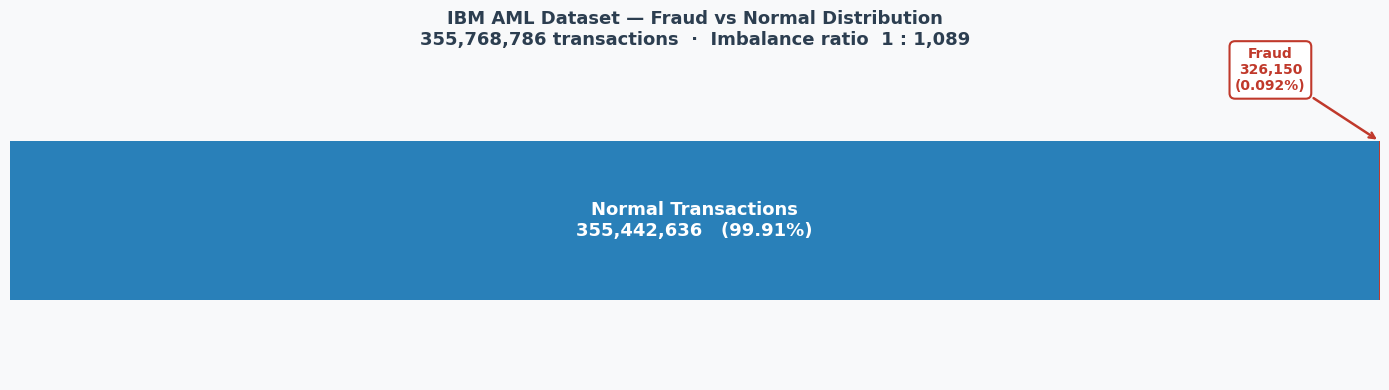

✅ Saved: fraud_distribution.png


In [7]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

print("📂 Loading from parquet parts...")

all_files = (
    glob.glob("../data/raw/HI_parquet_parts/*.parquet") +
    glob.glob("../data/raw/LI_parquet_parts/*.parquet")
)
print(f"   Found {len(all_files)} files")

counts = []
for f in all_files:
    chunk = pd.read_parquet(f, columns=['Is Laundering'])
    counts.append(chunk['Is Laundering'].value_counts())
    del chunk

result   = pd.concat(counts).groupby(level=0).sum()
total    = result.sum()
n_fraud  = result.get(1, 0)
n_norm   = result.get(0, 0)

print(f"✅ {total:,} transactions | Fraud: {n_fraud:,} | Normal: {n_norm:,}")

fig, ax = plt.subplots(figsize=(14, 4), facecolor='#F8F9FA')
ax.set_facecolor('#F8F9FA')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')

fraud_pct = n_fraud / total
norm_pct  = n_norm  / total

ax.barh(0.5, norm_pct, height=0.5, color='#2980B9', left=0, zorder=3)
ax.barh(0.5, fraud_pct, height=0.5, color='#C0392B',
        left=norm_pct, zorder=4)

ax.text(norm_pct / 2, 0.5,
        f'Normal Transactions\n{n_norm:,}   ({norm_pct*100:.2f}%)',
        ha='center', va='center', fontsize=13,
        color='white', fontweight='bold')

ax.annotate(
    f'Fraud\n{n_fraud:,}\n({fraud_pct*100:.3f}%)',
    xy=(norm_pct + fraud_pct / 2, 0.75),
    xytext=(min(norm_pct + 0.08, 0.92), 0.91),
    ha='center', fontsize=10, color='#C0392B', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#C0392B', lw=1.8),
    bbox=dict(boxstyle='round,pad=0.4', fc='white',
              ec='#C0392B', lw=1.5)
)

ax.set_title(
    f'IBM AML Dataset — Fraud vs Normal Distribution\n'
    f'{total:,} transactions  ·  Imbalance ratio  1 : {int(n_norm/n_fraud):,}',
    fontsize=13, fontweight='bold', color='#2C3E50', pad=12
)

plt.tight_layout()
plt.savefig('fraud_distribution.png', dpi=180,
            bbox_inches='tight', facecolor='#F8F9FA')
plt.show()
print("✅ Saved: fraud_distribution.png")

📂 Loading from parquet parts...
   Found 213 files
✅ Total accounts : 4,029,619
   Fraud accounts : 187,294
   Normal accounts: 3,842,325


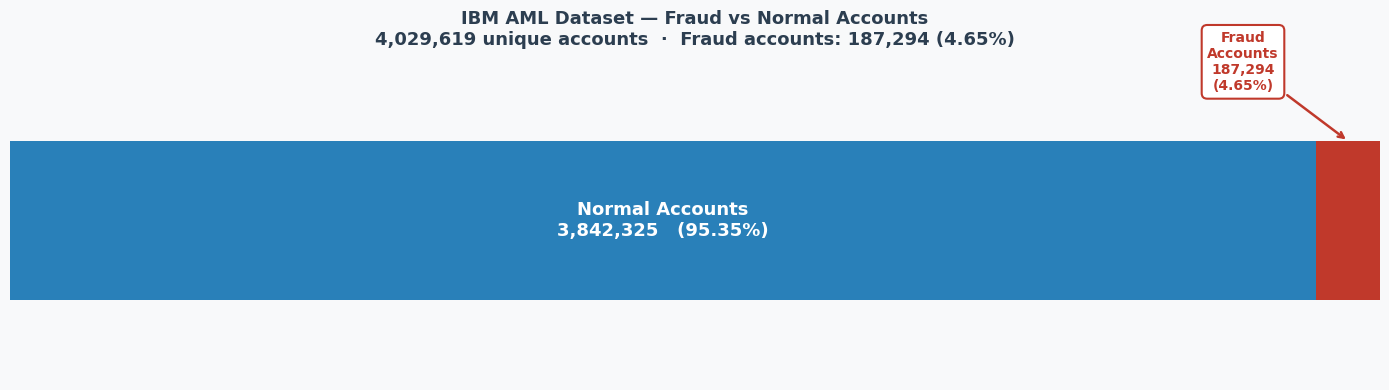

✅ Saved: accounts_distribution.png


In [8]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

print("📂 Loading from parquet parts...")

all_files = (
    glob.glob("../data/raw/HI_parquet_parts/*.parquet") +
    glob.glob("../data/raw/LI_parquet_parts/*.parquet")
)
print(f"   Found {len(all_files)} files")

fraud_accounts  = set()
normal_accounts = set()

for f in all_files:
    chunk = pd.read_parquet(f, columns=['Account', 'Is Laundering'])
    chunk['Account'] = chunk['Account'].astype(str).str.strip()
    fraud_accounts.update(chunk[chunk['Is Laundering'] == 1]['Account'].unique())
    normal_accounts.update(chunk[chunk['Is Laundering'] == 0]['Account'].unique())
    del chunk

# حساب عندو تحويلات fraud وnormal → normal only
normal_only = normal_accounts - fraud_accounts
fraud_set   = fraud_accounts

n_fraud_acc  = len(fraud_set)
n_normal_acc = len(normal_only)
total_acc    = n_fraud_acc + n_normal_acc

print(f"✅ Total accounts : {total_acc:,}")
print(f"   Fraud accounts : {n_fraud_acc:,}")
print(f"   Normal accounts: {n_normal_acc:,}")

fig, ax = plt.subplots(figsize=(14, 4), facecolor='#F8F9FA')
ax.set_facecolor('#F8F9FA')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')

fraud_pct  = n_fraud_acc  / total_acc
normal_pct = n_normal_acc / total_acc

ax.barh(0.5, normal_pct, height=0.5, color='#2980B9', left=0, zorder=3)
ax.barh(0.5, fraud_pct,  height=0.5, color='#C0392B',
        left=normal_pct, zorder=4)

ax.text(normal_pct / 2, 0.5,
        f'Normal Accounts\n{n_normal_acc:,}   ({normal_pct*100:.2f}%)',
        ha='center', va='center', fontsize=13,
        color='white', fontweight='bold')

ax.annotate(
    f'Fraud\nAccounts\n{n_fraud_acc:,}\n({fraud_pct*100:.2f}%)',
    xy=(normal_pct + fraud_pct / 2, 0.75),
    xytext=(min(normal_pct + 0.1, 0.90), 0.91),
    ha='center', fontsize=10, color='#C0392B', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#C0392B', lw=1.8),
    bbox=dict(boxstyle='round,pad=0.4', fc='white',
              ec='#C0392B', lw=1.5)
)

ax.set_title(
    f'IBM AML Dataset — Fraud vs Normal Accounts\n'
    f'{total_acc:,} unique accounts  ·  '
    f'Fraud accounts: {n_fraud_acc:,} ({fraud_pct*100:.2f}%)',
    fontsize=13, fontweight='bold', color='#2C3E50', pad=12
)

plt.tight_layout()
plt.savefig('accounts_distribution.png', dpi=180,
            bbox_inches='tight', facecolor='#F8F9FA')
plt.show()
print("✅ Saved: accounts_distribution.png")

## 📂 2.1 Scan all files
> قراءة كل الـ 213 ملف — بس 3 أعمدة (Account, Timestamp, Is Laundering)

In [9]:
import pandas as pd
import glob
import os
import gc
import numpy as np
from collections import defaultdict

CACHE_SCAN = "df_scan_cache.parquet"
CACHE_COMBINED = "df_combined_cache.parquet"

LI_FOLDER = "../data/raw/LI_parquet_parts"
HI_FOLDER = "../data/raw/HI_parquet_parts"

li_files = sorted(glob.glob(os.path.join(LI_FOLDER, "*.parquet")))
hi_files = sorted(glob.glob(os.path.join(HI_FOLDER, "*.parquet")))
all_files = li_files + hi_files
print(f" Total: {len(all_files)} files (LI: {len(li_files)} + HI: {len(hi_files)})")

if os.path.exists(CACHE_COMBINED):
    print("✅ Cache exists — skip scan")
else:
    print("\n Scanning all files...")
    account_months = defaultdict(set)
    fraud_accounts = set()
    fraud_tx_count = 0

    for idx, f in enumerate(all_files):
        chunk = pd.read_parquet(f, columns=["Account", "Timestamp", "Is Laundering"])
        chunk["Account"] = chunk["Account"].astype(str).str.strip()
        ts = pd.to_datetime(chunk["Timestamp"])
        chunk["ym"] = (ts.dt.year * 100 + ts.dt.month).astype(str)

        pairs = chunk[["Account", "ym"]].drop_duplicates()
        for a, ym in zip(pairs["Account"].values, pairs["ym"].values):
            account_months[a].add(ym)

        fraud_in_chunk = chunk[chunk["Is Laundering"] == 1]
        fraud_accounts.update(fraud_in_chunk["Account"].unique())
        fraud_tx_count += len(fraud_in_chunk)

        del chunk, pairs, ts, fraud_in_chunk
        gc.collect()
        if (idx + 1) % 30 == 0 or idx == len(all_files) - 1:
            print(f"  {idx+1}/{len(all_files)} files | {len(account_months)} accounts | {len(fraud_accounts)} fraud accounts | {fraud_tx_count:,} fraud tx")

    print(f"\n✅ Scan done:")
    print(f"  Total accounts: {len(account_months):,}")
    print(f"  Fraud accounts (has Is Laundering=1): {len(fraud_accounts):,}")
    print(f"  Total fraud transactions: {fraud_tx_count:,}")


 Total: 213 files (LI: 177 + HI: 36)

 Scanning all files...
  30/213 files | 1860279 accounts | 10752 fraud accounts | 15,755 fraud tx
  60/213 files | 1893248 accounts | 24269 fraud accounts | 36,035 fraud tx
  90/213 files | 1965888 accounts | 34495 fraud accounts | 52,584 fraud tx
  120/213 files | 2011100 accounts | 43324 fraud accounts | 68,485 fraud tx
  150/213 files | 2021696 accounts | 52080 fraud accounts | 84,503 fraud tx
  180/213 files | 3945020 accounts | 70725 fraud accounts | 116,191 fraud tx
  210/213 files | 4028847 accounts | 178373 fraud accounts | 307,641 fraud tx
  213/213 files | 4029619 accounts | 187294 fraud accounts | 326,150 fraud tx

✅ Scan done:
  Total accounts: 4,029,619
  Fraud accounts (has Is Laundering=1): 187,294
  Total fraud transactions: 326,150


In [10]:
os.path.exists(CACHE_COMBINED)

False

## 📂 2.2 Select accounts
> اختيار الحسابات اللي عندها سجل شهري + فيها احتيال

In [11]:
MIN_MONTHS = 2

if not os.path.exists(CACHE_COMBINED):

    fraud_qualified = [a for a in fraud_accounts if len(account_months[a]) >= MIN_MONTHS]
    fraud_unqualified = [a for a in fraud_accounts if len(account_months[a]) < MIN_MONTHS]

    print(f"Fraud accounts with {MIN_MONTHS}+ months: {len(fraud_qualified)}")
    print(f"Fraud accounts with <{MIN_MONTHS} months: {len(fraud_unqualified)}")

    selected_fraud = list(fraud_accounts)

    normal_accounts = {a: len(m) for a, m in account_months.items() 
                       if a not in fraud_accounts and len(m) >= MIN_MONTHS}
    normal_sorted = sorted(normal_accounts.items(), key=lambda x: x[1], reverse=True)
    selected_normal = [a for a, _ in normal_sorted[:50000]]  

    print(f"\n✅ Fraud accounts: {len(selected_fraud):,}")
    print(f"✅ Normal accounts: {len(selected_normal):,}")
    print(f" Sample 30,000 transactions will be done later")

    selected_set = set(selected_fraud + selected_normal)

    del account_months, fraud_accounts, normal_accounts, normal_sorted
    gc.collect()
else:
    print("✅ Cache exists — skip selection")


Fraud accounts with 2+ months: 185813
Fraud accounts with <2 months: 1481

✅ Fraud accounts: 187,294
✅ Normal accounts: 50,000
 Sample 30,000 transactions will be done later


## 📂 2.3 Load transactions
> تحميل كل تحويلات الحسابات المختارة وحفظها بالكاش

In [12]:
if os.path.exists(CACHE_COMBINED):
    df_combined = pd.read_parquet(CACHE_COMBINED)
    print("✅ Loaded from cache:", df_combined.shape)
else:
    print(f"\n Loading transactions for {len(selected_set):,} accounts...")
    parts = []
    total_rows = 0
    for idx, f in enumerate(all_files):
        chunk = pd.read_parquet(f)
        chunk["Account"] = chunk["Account"].astype(str).str.strip()
        filtered = chunk[chunk["Account"].isin(selected_set)]
        if len(filtered) > 0:
            parts.append(filtered)
            total_rows += len(filtered)
        del chunk
        gc.collect()
        if (idx + 1) % 30 == 0 or idx == len(all_files) - 1:
            print(f"  {idx+1}/{len(all_files)} files | {total_rows:,} rows")

    df_combined = pd.concat(parts, ignore_index=True)
    del parts
    gc.collect()

    df_combined.to_parquet(CACHE_COMBINED, index=False)
    print(f"\n✅ Saved to cache: {df_combined.shape}")

fraud_count = (df_combined["Is Laundering"] == 1).sum()
normal_count = (df_combined["Is Laundering"] == 0).sum()
print(f"\n{'='*50}")
print(f" Shape: {df_combined.shape}")
print(f" Accounts: {df_combined['Account'].astype(str).nunique():,}")
print(f"Fraud transactions: {fraud_count:,}")
print(f" Normal transactions: {normal_count:,}")
print(f" Fraud rate: {fraud_count / len(df_combined):.2%}")



 Loading transactions for 237,294 accounts...
  30/213 files | 7,231,702 rows
  60/213 files | 14,891,556 rows
  90/213 files | 21,921,849 rows
  120/213 files | 29,487,433 rows
  150/213 files | 36,812,812 rows
  180/213 files | 46,629,782 rows
  210/213 files | 77,894,177 rows
  213/213 files | 81,125,801 rows

✅ Saved to cache: (81125801, 12)

 Shape: (81125801, 12)
 Accounts: 237,294
Fraud transactions: 326,150
 Normal transactions: 80,799,651
 Fraud rate: 0.40%


In [13]:
import pandas as pd

total_accounts = df_combined['Account'].astype(str).nunique()
fraud_accounts_count = df_combined[df_combined['Is Laundering']==1]['Account'].astype(str).nunique()
fraud_tx_count = (df_combined['Is Laundering']==1).sum()

print("✅ Scan done:")
print(f"  Total accounts: {total_accounts:,}")
print(f"  Fraud accounts (has Is Laundering=1): {fraud_accounts_count:,}")
print(f"  Total fraud transactions: {fraud_tx_count:,}")



✅ Scan done:
  Total accounts: 237,294
  Fraud accounts (has Is Laundering=1): 187,294
  Total fraud transactions: 326,150


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

df_plot = df_combined.sample(n=200000, random_state=42)
df_plot['Timestamp'] = pd.to_datetime(df_plot['Timestamp'])
print(f"Plotting sample: {df_plot.shape}")

Plotting sample: (200000, 12)


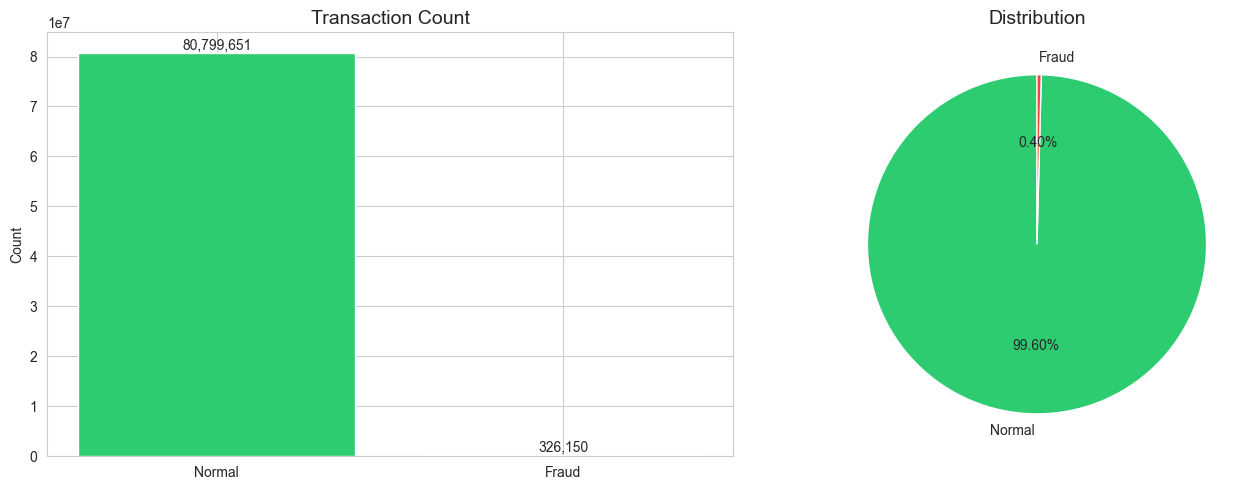

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = df_combined['Is Laundering'].value_counts()
axes[0].bar(['Normal', 'Fraud'], counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Transaction Count', fontsize=14)
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')

axes[1].pie(counts.values, labels=['Normal', 'Fraud'], 
            colors=['#2ecc71', '#e74c3c'], autopct='%1.2f%%', startangle=90)
axes[1].set_title('Distribution', fontsize=14)

plt.tight_layout()
plt.show()

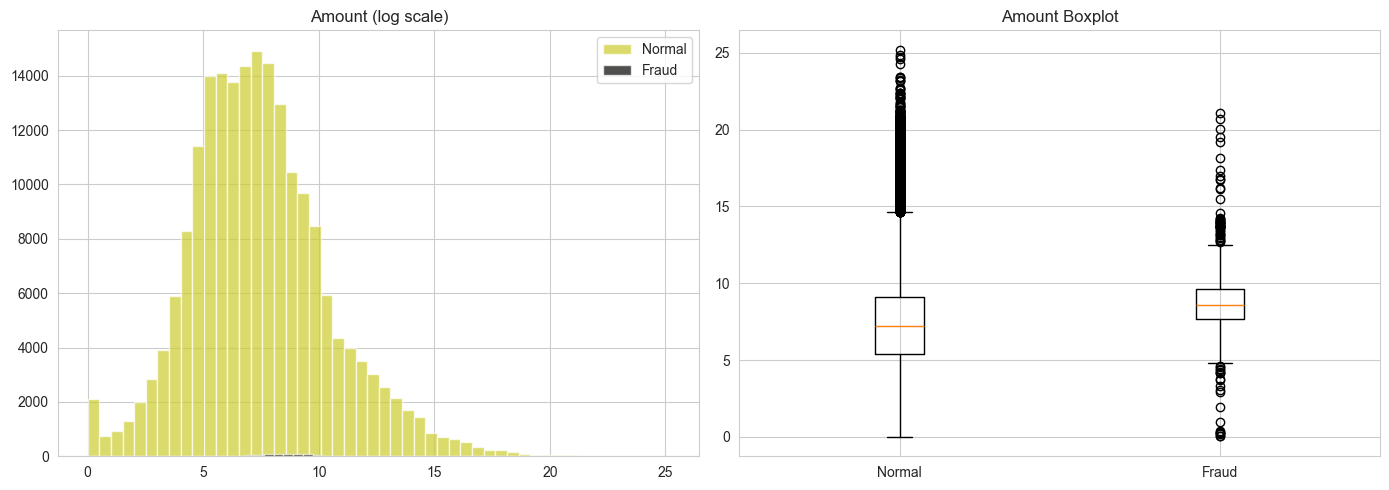

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
normal = df_plot[df_plot['Is Laundering']==0]['Amount Paid']
fraud = df_plot[df_plot['Is Laundering']==1]['Amount Paid']

axes[0].hist(np.log1p(normal), bins=50, color="#cccc2e", alpha=0.7, label='Normal')
axes[0].hist(np.log1p(fraud), bins=50, color="#050603", alpha=0.7, label='Fraud')
axes[0].set_title('Amount (log scale)')
axes[0].legend()

axes[1].boxplot([np.log1p(normal), np.log1p(fraud)], labels=['Normal', 'Fraud'])
axes[1].set_title('Amount Boxplot')
plt.tight_layout()
plt.show()

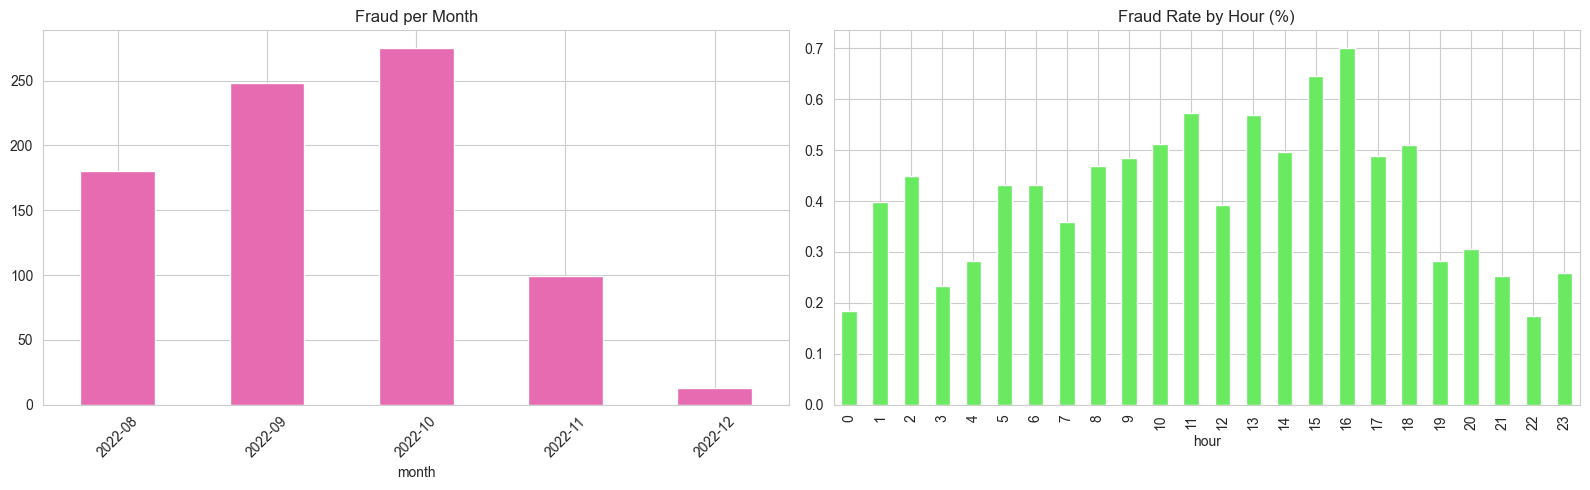

In [17]:
df_plot['month'] = df_plot['Timestamp'].dt.to_period('M').astype(str)
df_plot['hour'] = df_plot['Timestamp'].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df_plot.groupby('month')['Is Laundering'].sum().plot(kind='bar', color="#e76bb1", ax=axes[0])
axes[0].set_title('Fraud per Month')
axes[0].tick_params(axis='x', rotation=45)

(df_plot.groupby('hour')['Is Laundering'].mean()*100).plot(kind='bar', color="#69ea60", ax=axes[1])
axes[1].set_title('Fraud Rate by Hour (%)')
plt.tight_layout()
plt.show()

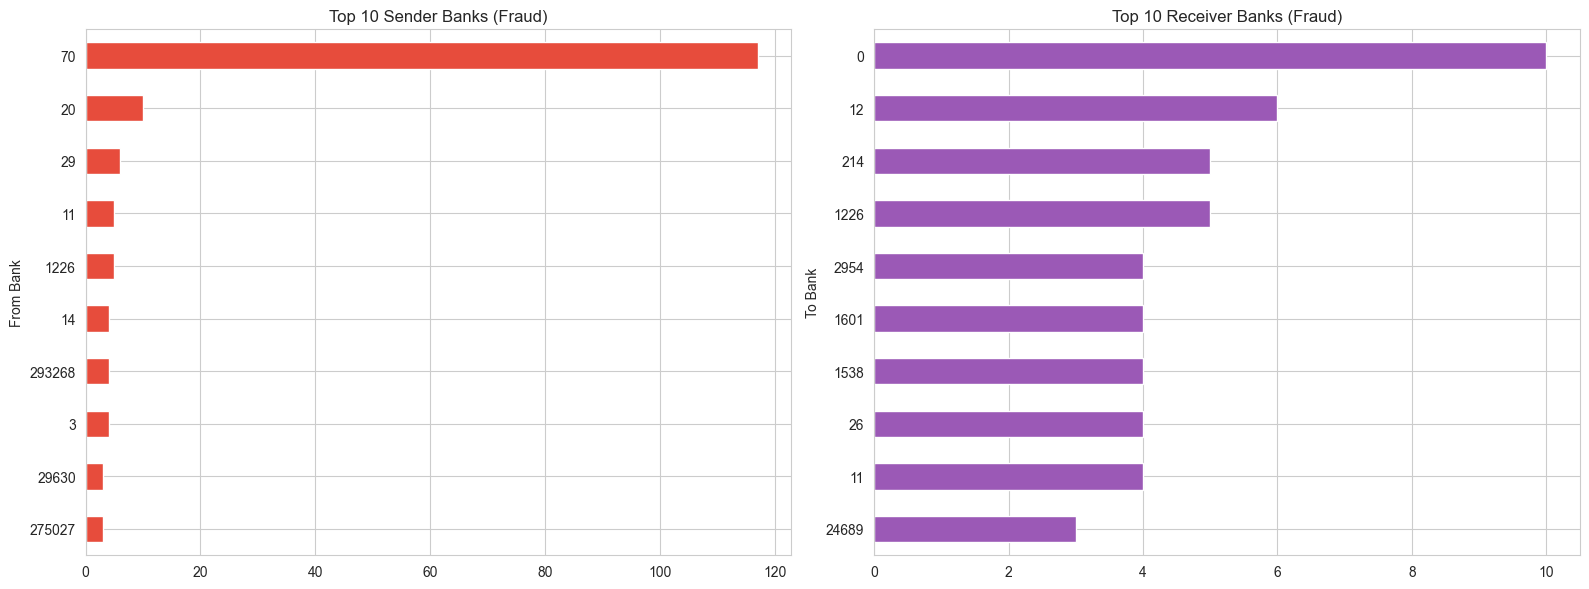

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
df_plot[df_plot['Is Laundering']==1]['From Bank'].value_counts().head(10).plot(
    kind='barh', color='#e74c3c', ax=axes[0])
axes[0].set_title('Top 10 Sender Banks (Fraud)')
axes[0].invert_yaxis()

df_plot[df_plot['Is Laundering']==1]['To Bank'].value_counts().head(10).plot(
    kind='barh', color='#9b59b6', ax=axes[1])
axes[1].set_title('Top 10 Receiver Banks (Fraud)')
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

In [19]:
os.path.exists(CACHE_COMBINED)

True

## 🎯 3. Sample & Merge

In [20]:
CACHE_FEATURES = "df_merged_features.parquet"

if not os.path.exists(CACHE_FEATURES):
    df_fraud  = df_combined[df_combined["Is Laundering"] == 1]
    df_normal = df_combined[df_combined["Is Laundering"] == 0]
    
    n_fraud = len(df_fraud)
    n_target = 30000
    
    print(f" Available fraud: {n_fraud:,}")
    print(f" Available normal: {len(df_normal):,}")
    
    if n_fraud >= 10000:
        df_fraud_sample = df_fraud.sample(n=10000, random_state=42)
        df_normal_sample = df_normal.sample(n=20000, random_state=42)
    else:
    
        df_fraud_sample = df_fraud
        n_normal_needed = n_target - n_fraud
        df_normal_sample = df_normal.sample(n=min(n_normal_needed, len(df_normal)), random_state=42)
    
    df_sample = pd.concat([df_fraud_sample, df_normal_sample], ignore_index=True)
    df_sample = df_sample.sample(frac=1, random_state=42).reset_index(drop=True)
    
    print(f"\n✅ Sample: {len(df_sample):,} transactions")
    print(f"  Fraud: {(df_sample['Is Laundering']==1).sum():,}")
    print(f"  Normal: {(df_sample['Is Laundering']==0).sum():,}")
    print(f"  Fraud rate: {df_sample['Is Laundering'].mean():.2%}")
    print(f"  Accounts: {df_sample['Account'].astype(str).nunique():,}")
else:
    df_merged = pd.read_parquet(CACHE_FEATURES)
    print(f"⚡ Cache found — loaded df_merged: {df_merged.shape}")


 Available fraud: 326,150
 Available normal: 80,799,651

✅ Sample: 30,000 transactions
  Fraud: 10,000
  Normal: 20,000
  Fraud rate: 33.33%
  Accounts: 18,201


In [21]:
if not os.path.exists(CACHE_FEATURES):
    df_sample['Timestamp'] = pd.to_datetime(df_sample['Timestamp'])
    df_sample['year']  = df_sample['Timestamp'].dt.year
    df_sample['month'] = df_sample['Timestamp'].dt.month
    df_sample['day']   = df_sample['Timestamp'].dt.day
    df_sample['hour']  = df_sample['Timestamp'].dt.hour
    df_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Timestamp           30000 non-null  datetime64[ns]
 1   From Bank           30000 non-null  int64         
 2   Account             30000 non-null  object        
 3   To Bank             30000 non-null  int64         
 4   Account.1           30000 non-null  object        
 5   Amount Received     30000 non-null  float64       
 6   Receiving Currency  30000 non-null  object        
 7   Amount Paid         30000 non-null  float64       
 8   Payment Currency    30000 non-null  object        
 9   Payment Format      30000 non-null  object        
 10  Is Laundering       30000 non-null  int64         
 11  source              30000 non-null  object        
 12  year                30000 non-null  int32         
 13  month               30000 non-null  int32     

In [22]:
if not os.path.exists(CACHE_FEATURES):
    df_sample['Account'] = df_sample['Account'].astype(str).str.strip()
    vip_accounts = df_sample['Account'].unique()
    pd.Series(vip_accounts).to_csv('vip_accounts.csv', index=False)
    print(f"vip_accounts saved: {len(vip_accounts)} accounts")

vip_accounts saved: 18201 accounts


In [23]:
if not os.path.exists(CACHE_FEATURES):
    df_acc_hi = pd.read_csv("../data/raw/HI-Large_accounts.csv")
    df_acc_li = pd.read_csv("../data/raw/LI-Large_accounts.csv")
    
    for df in [df_acc_hi, df_acc_li]:
        df.columns = df.columns.str.strip()
        df.columns = ["BankName", "BankID", "AccountNumber", "EntityID", "EntityName"]
    
    df_accounts_all = pd.concat([df_acc_hi, df_acc_li], ignore_index=True)
    df_accounts_all = df_accounts_all.drop_duplicates(subset=["AccountNumber"])
    
    df_sample['Account'] = df_sample['Account'].astype(str).str.strip()
    df_accounts_all["AccountNumber"] = df_accounts_all["AccountNumber"].astype(str).str.strip()
    df_accounts_all["EntityName"] = df_accounts_all["EntityName"].str.replace(r"#\d+", "", regex=True).str.strip()
    
    entity_map = {
        "Corporation": 3, "Sole Proprietorship": 2, "Partnership": 2,
        "Direct": 1, "Individual": 1, "Country": 2
    }

    sample_accounts = df_sample["Account"].astype(str).str.strip().unique()
    df_accounts_final = df_accounts_all[
        df_accounts_all["AccountNumber"].isin(sample_accounts)
    ].copy()

    df_accounts_final['entity_type_score'] = df_accounts_final['EntityName'].map(entity_map).fillna(1).astype(int)
    
    print(f" Total accounts: {len(df_accounts_all):,}")
    print(f" Matched with sample: {len(df_accounts_final):,}")
    print(f" entity_type_score: {df_accounts_final['entity_type_score'].value_counts().to_dict()}")
    
    del df_accounts_all, df_acc_hi, df_acc_li
    gc.collect()

 Total accounts: 4,109,786
 Matched with sample: 18,201
 entity_type_score: {2: 11795, 3: 6362, 1: 44}


In [24]:
if not os.path.exists(CACHE_FEATURES):
    df_merged = pd.merge(
        df_sample,
        df_accounts_final,
        left_on='Account',
        right_on='AccountNumber',
        how='left'
    )
    print(f"after Merge: {df_merged.shape}")
    print(f"NaN: {df_merged.isnull().sum().sum()}")

after Merge: (30000, 22)
NaN: 0


In [25]:
import os
for f in ["df_combined_cache.parquet", "df_merged_features.parquet",
          "rf_aml_model.pkl", "xgb_aml_model.pkl"]:
    if os.path.exists(f):
        print(f"📁 موجود: {f}")
    else:
        print(f"✅ ممسوح: {f}")

📁 موجود: df_combined_cache.parquet
✅ ممسوح: df_merged_features.parquet
✅ ممسوح: rf_aml_model.pkl
✅ ممسوح: xgb_aml_model.pkl


In [26]:
print("Account column sample:")
print(df_merged['Account'].head(10))
print(f"\nUnique accounts: {df_merged['Account'].nunique()}")

Account column sample:
0    801C00100
1    8078E53F0
2    801F89B50
3    816FA5910
4    1004286A8
5    81F942360
6    8080B6EC0
7    806D99E30
8    8214C9870
9    10042B6A8
Name: Account, dtype: object

Unique accounts: 18201


## 🔧 4. Feature Engineering

In [27]:
if not os.path.exists(CACHE_FEATURES):
    df_merged = df_merged.sort_values(['Account', 'Timestamp']).reset_index(drop=True)

    df_merged['prev_mean_amount'] = (
        df_merged.groupby('Account')['Amount Paid']
        .transform(lambda x: x.expanding().mean().shift(1))
    )
    df_merged['prev_max_amount'] = (
        df_merged.groupby('Account')['Amount Paid']
        .transform(lambda x: x.expanding().max().shift(1))
    )
    df_merged['transaction_count'] = df_merged.groupby('Account').cumcount() + 1

    # Missing value handling (academic justification):
    # prev_mean / prev_max are NaN for the first transaction of each account
    # (no prior history exists). We fill with the current transaction's amount,
    # treating the first transaction as its own baseline — a common approach in
    # rolling-window feature engineering (Bahnsen et al., 2016).
    df_merged['prev_mean_amount'] = df_merged['prev_mean_amount'].fillna(df_merged['Amount Paid'])
    df_merged['prev_max_amount']  = df_merged['prev_max_amount'].fillna(df_merged['Amount Paid'])

    df_merged['amount_to_mean_ratio'] = (
        df_merged['Amount Paid'] / df_merged['prev_mean_amount'].replace(0, np.nan)
    )
    df_merged['amount_to_max_ratio'] = (
        df_merged['Amount Paid'] / df_merged['prev_max_amount'].replace(0, np.nan)
    )

    # Ratios are NaN only if prev values are 0 after fillna (edge case).
    # Fill with 1.0 = neutral ratio (current equals historical baseline).
    df_merged['amount_to_mean_ratio'] = df_merged['amount_to_mean_ratio'].replace([np.inf, -np.inf], np.nan).fillna(1.0)
    df_merged['amount_to_max_ratio']  = df_merged['amount_to_max_ratio'].replace([np.inf, -np.inf], np.nan).fillna(1.0)
    df_merged

In [28]:
if not os.path.exists(CACHE_FEATURES):
    segment_limit_map = (
        df_merged.groupby(['BankName', 'Payment Format'])['Amount Paid']
        .quantile(0.95)
    )
    df_merged['upper_limit'] = np.where(
        df_merged.groupby('Account')['Amount Paid'].transform('count') > 5,
        df_merged.groupby('Account')['Amount Paid'].transform(lambda x: x.quantile(0.95)),
        df_merged.set_index(['BankName', 'Payment Format']).index.map(segment_limit_map)
    )

    # Missing value handling:
    # upper_limit is NaN when a BankName+PaymentFormat segment has fewer than
    # the required observations. We apply a two-level fallback:
    #   1st fallback: account-level 95th percentile (account-specific context)
    #   2nd fallback: global 95th percentile (conservative population-level bound)
    # This preserves contextual meaning at each level (hierarchical imputation).
    account_q95 = df_merged.groupby('Account')['Amount Paid'].transform(lambda x: x.quantile(0.95))
    global_q95  = df_merged['Amount Paid'].quantile(0.95)
    df_merged['upper_limit'] = (
        df_merged['upper_limit']
        .fillna(account_q95)
        .fillna(global_q95)
    )

    df_merged['is_abnormal'] = (df_merged['Amount Paid'] > df_merged['upper_limit']).astype(int)
    print(df_merged['is_abnormal'].value_counts())

is_abnormal
0    26493
1     3507
Name: count, dtype: int64


In [29]:
if not os.path.exists(CACHE_FEATURES):
    df_merged['prev_time'] = (
        df_merged.groupby('Account')['Timestamp']
        .transform(lambda x: x.shift(1).dt.strftime('%m-%d %H:%M'))
    )
    df_merged['time_diff'] = (
        df_merged.groupby('Account')['Timestamp']
        .transform(lambda x: x.diff().dt.total_seconds())
    )
    df_merged['transactions_per_hour'] = (
        df_merged.groupby(['Account', 'day', 'hour'])['Amount Paid'].transform('count')
    )
    df_merged['transactions_per_day'] = (
        df_merged.groupby(['Account', 'day'])['Amount Paid'].transform('count')
    )
    df_merged['avg_time_diff'] = df_merged.groupby('Account')['time_diff'].transform('mean')

    # Missing value handling:
    # time_diff is NaN for the first transaction (no previous timestamp).
    # Value 0 is semantically correct: no elapsed time before the first event.
    # avg_time_diff is NaN for accounts with a single transaction.
    # We impute with the population median — a robust central tendency measure
    # unaffected by extreme outliers (Sterne & White, 2009).
    median_time_diff = df_merged['avg_time_diff'].median()
    df_merged['time_diff']     = df_merged['time_diff'].fillna(0)
    df_merged['avg_time_diff'] = df_merged['avg_time_diff'].fillna(median_time_diff)
    
    # prev_time NaN = first transaction for this account (no prior timestamp)
    # We fill with the transaction's own timestamp as a self-reference baseline
    df_merged['prev_time'] = df_merged['prev_time'].fillna(
    df_merged['Timestamp'].dt.strftime('%m-%d %H:%M')
)

    df_merged['is_faster_than_normal'] = (
        df_merged['time_diff'] < df_merged['avg_time_diff']
    ).astype(int)

    account_95 = df_merged.groupby('Account')['Amount Paid'].quantile(0.95)
    df_merged['is_large_amount'] = (
        df_merged['Amount Paid'] > df_merged['Account'].map(account_95)
    ).astype(int)
    df_merged['behavior_score'] = df_merged['is_faster_than_normal'] + df_merged['is_large_amount']
    df_merged

In [30]:
if not os.path.exists(CACHE_FEATURES):
    df_merged['Account.1'] = df_merged['Account.1'].astype(str).str.strip()
    df_merged['unique_receivers'] = df_merged.groupby('Account')['Account.1'].transform('nunique')

    receiver_counts = df_merged.groupby(['Account', 'Account.1']).size().reset_index(name='recv_count')
    df_merged = pd.merge(df_merged, receiver_counts, on=['Account', 'Account.1'], how='left')
    df_merged['repeat_receiver'] = (df_merged['recv_count'] > 1).astype(int)

    df_merged['is_cross_bank'] = (df_merged['From Bank'] != df_merged['To Bank']).astype(int)
    
    receiver_freq = df_merged.groupby('Account.1').size().reset_index(name='receiver_risk_count')
    df_merged = pd.merge(df_merged, receiver_freq, on='Account.1', how='left')
    df_merged['receiver_risk_count'] = df_merged['receiver_risk_count'].fillna(0)
    
    print("✅ Network features done")


✅ Network features done


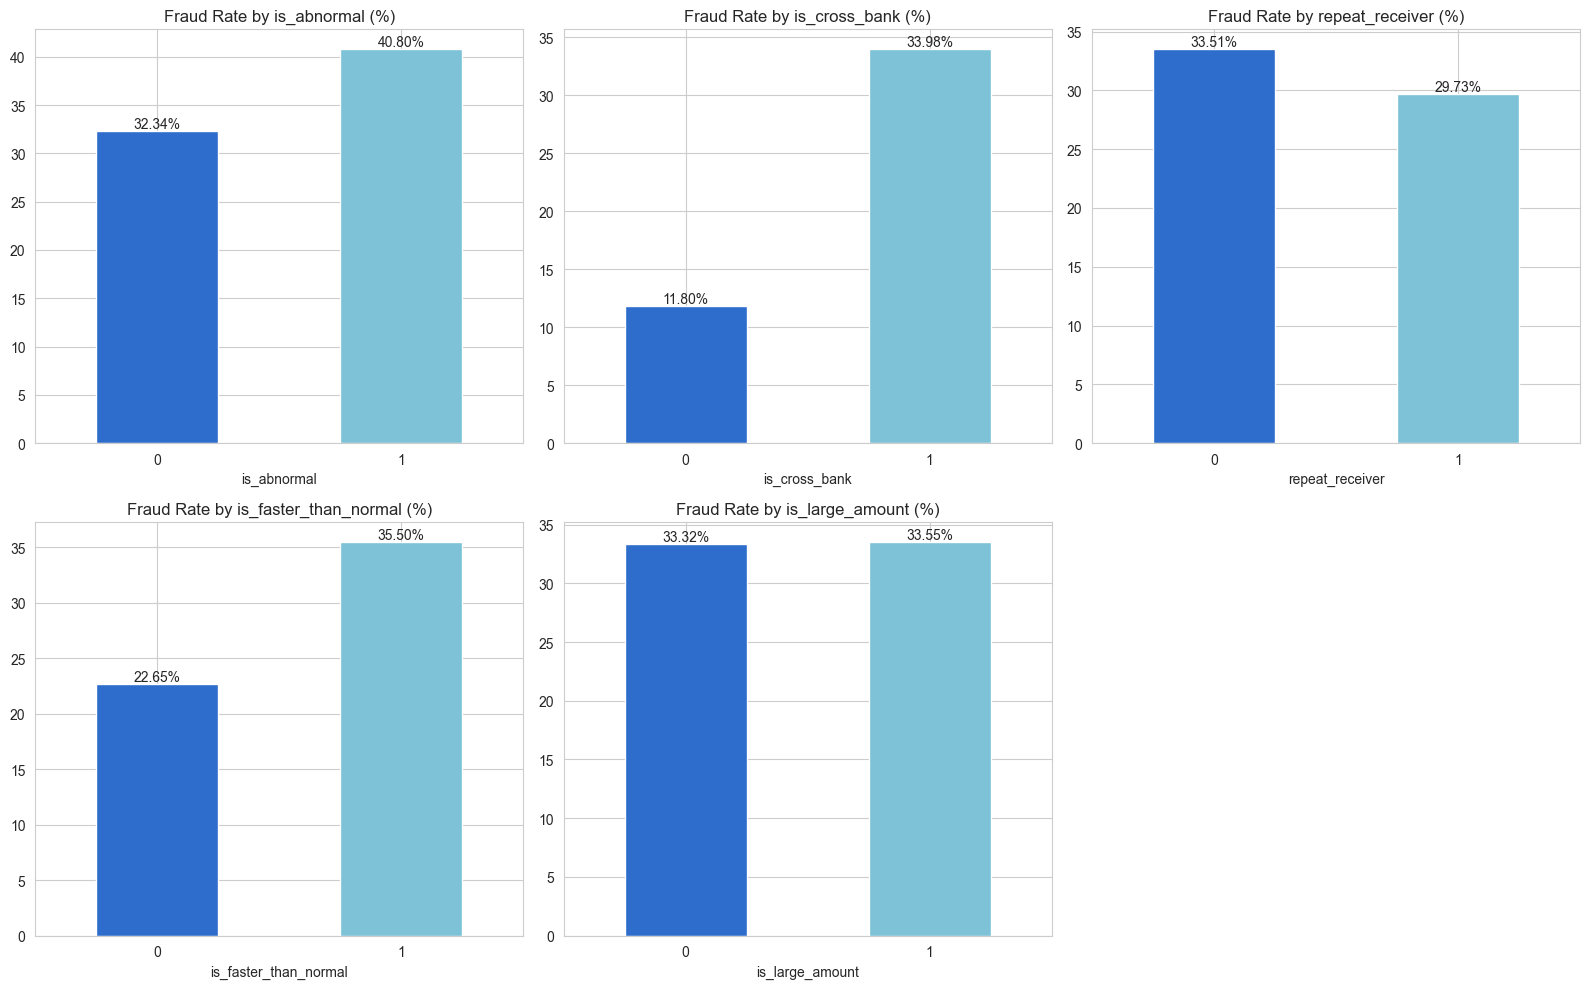

In [31]:
features = ['is_abnormal', 'is_cross_bank', 'repeat_receiver', 
            'is_faster_than_normal', 'is_large_amount']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for ax, col in zip(axes, features):
    rates = df_merged.groupby(col)['Is Laundering'].mean() * 100
    rates.plot(kind='bar', ax=ax, color=["#2e6dcc", "#7dc2d7"])
    ax.set_title(f'Fraud Rate by {col} (%)')
    ax.tick_params(axis='x', rotation=0)
    for i, v in enumerate(rates.values):
        ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom')
axes[-1].axis('off')
plt.tight_layout()
plt.show()


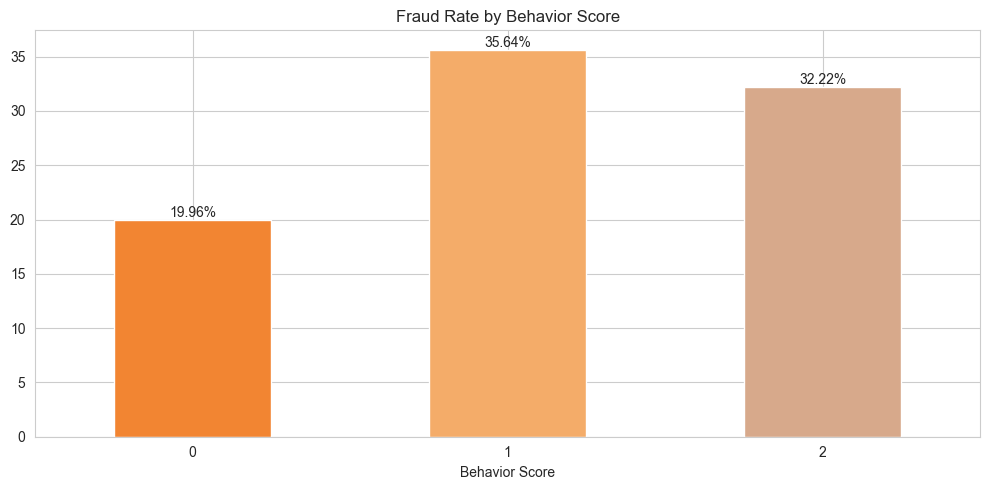

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))
scores = df_merged.groupby('behavior_score')['Is Laundering'].mean() * 100
scores.plot(kind='bar', color=["#f28532", "#f4ac69", "#D7A98B"], ax=ax)
ax.set_title('Fraud Rate by Behavior Score')
ax.set_xlabel('Behavior Score')
ax.tick_params(axis='x', rotation=0)
for i, v in enumerate(scores.values):
    ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()


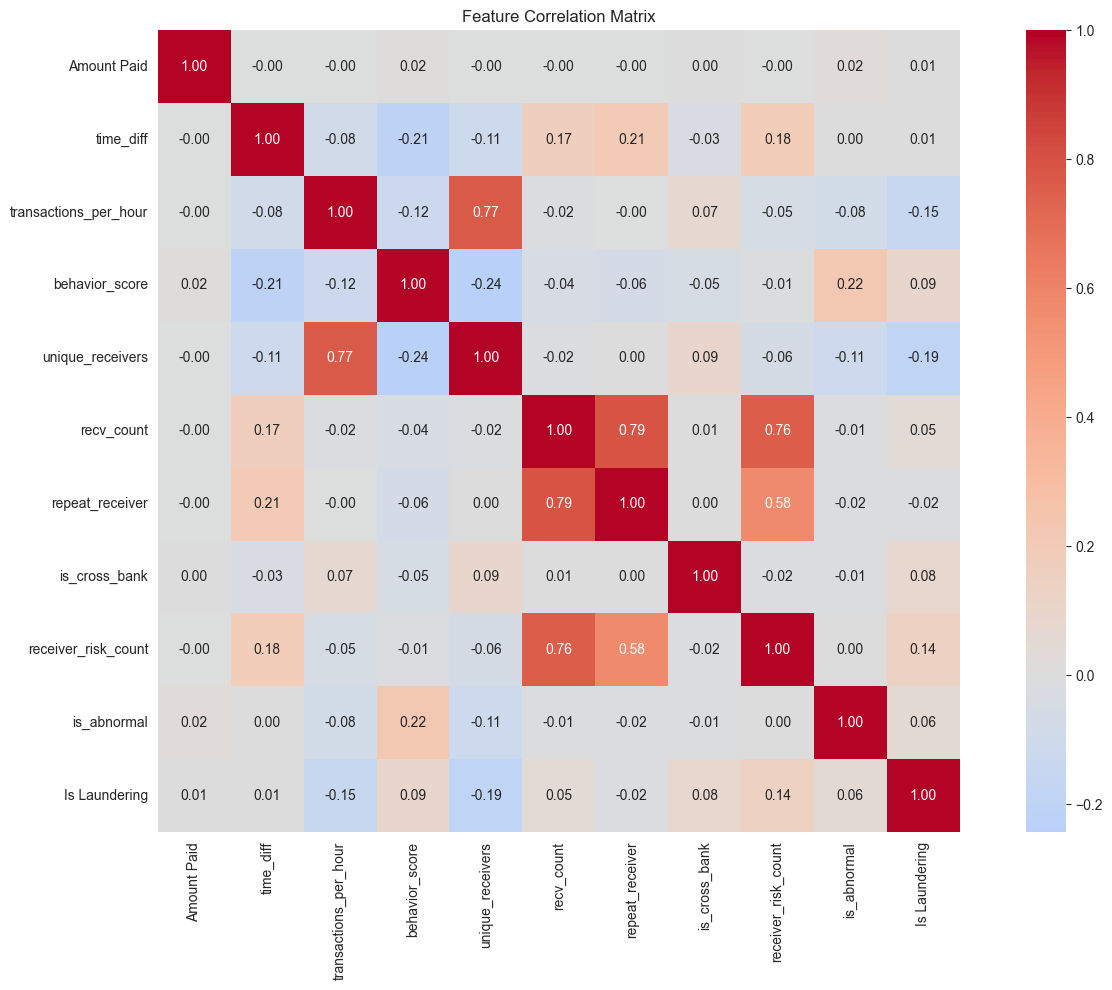

In [33]:
cols = ['Amount Paid', 'time_diff', 'transactions_per_hour', 'behavior_score',
        'unique_receivers', 'recv_count', 'repeat_receiver', 'is_cross_bank',
        'receiver_risk_count', 'is_abnormal', 'Is Laundering']
available = [c for c in cols if c in df_merged.columns]

plt.figure(figsize=(14, 10))
sns.heatmap(df_merged[available].corr(), annot=True, cmap='coolwarm', 
            center=0, fmt='.2f', square=True)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()


In [34]:
if not os.path.exists(CACHE_FEATURES):
    df_merged['currency_mismatch'] = (
        df_merged['Payment Currency'] != df_merged['Receiving Currency']
    ).astype(int)
    df_merged['amount_ratio_recv_paid'] = (
        df_merged['Amount Received'] / df_merged['Amount Paid'].replace(0, np.nan)
    ).fillna(1.0)

    print("✅ Currency features done")
else:
    print(" Cache found — skipping currency features")


✅ Currency features done


## 📅 Multi-Period Behavior Tracking
> تتبع سلوك العميل على كل المستويات: شهري، يومي، ساعي، وسنوي
> كل حساب مختار عنده سجل شهري (شهرين على الأقل) عشان نقدر نتتبع التغيرات

In [35]:
if not os.path.exists(CACHE_FEATURES):
    df_merged['Timestamp'] = pd.to_datetime(df_merged['Timestamp'])
    df_merged['year_month'] = df_merged['Timestamp'].dt.to_period('M')
    df_merged['year_val'] = df_merged['Timestamp'].dt.year

    monthly_stats = df_merged.groupby(['Account', 'year_month']).agg(
        monthly_tx_count=('Amount Paid', 'count'),
        monthly_total_amount=('Amount Paid', 'sum'),
        monthly_avg_amount=('Amount Paid', 'mean'),
        monthly_max_amount=('Amount Paid', 'max'),
        monthly_unique_receivers=('Account.1', 'nunique'),
        monthly_cross_bank=('is_cross_bank', 'sum'),
    ).reset_index()
    monthly_stats = monthly_stats.sort_values(['Account', 'year_month'])

  
    for col in ['monthly_tx_count', 'monthly_total_amount', 'monthly_avg_amount',
                'monthly_unique_receivers', 'monthly_cross_bank']:
        prev_col = f'prev_{col}'
        change_col = f'{col}_change_pct'
        monthly_stats[prev_col] = monthly_stats.groupby('Account')[col].shift(1)
        monthly_stats[change_col] = (
            (monthly_stats[col] - monthly_stats[prev_col]) / monthly_stats[prev_col].replace(0, 1)
        ).replace([np.inf, -np.inf], np.nan).fillna(0)
        # NaN = first month (no prior period). 0 = no change — conservative neutral baseline.


    monthly_stats['amount_spike'] = (monthly_stats['monthly_total_amount_change_pct'].abs() > 2).astype(int)
    monthly_stats['tx_count_spike'] = (monthly_stats['monthly_tx_count_change_pct'].abs() > 2).astype(int)
    monthly_stats['receiver_spike'] = (monthly_stats['monthly_unique_receivers_change_pct'].abs() > 2).astype(int)


    months_active = monthly_stats.groupby('Account')['year_month'].nunique().reset_index()
    months_active.columns = ['Account', 'months_active']

   
    latest_monthly = monthly_stats.sort_values('year_month').groupby('Account').last().reset_index()
    
    spike_totals = monthly_stats.groupby('Account').agg(
        total_amount_spikes=('amount_spike', 'sum'),
        total_tx_spikes=('tx_count_spike', 'sum'),
        total_receiver_spikes=('receiver_spike', 'sum'),
    ).reset_index()


    monthly_volatility = monthly_stats.groupby('Account').agg(
        monthly_amount_std=('monthly_total_amount', 'std'),
        monthly_tx_std=('monthly_tx_count', 'std'),
    ).fillna(0).reset_index()

    monthly_features_cols = [
        'monthly_tx_count', 'monthly_total_amount', 'monthly_avg_amount',
        'monthly_max_amount', 'monthly_unique_receivers', 'monthly_cross_bank',
        'monthly_total_amount_change_pct', 'monthly_tx_count_change_pct',
        'monthly_avg_amount_change_pct', 'monthly_unique_receivers_change_pct',
        'monthly_cross_bank_change_pct',
        'amount_spike', 'tx_count_spike', 'receiver_spike',
    ]

    df_merged = pd.merge(df_merged, latest_monthly[['Account'] + monthly_features_cols], on='Account', how='left')
    df_merged = pd.merge(df_merged, months_active, on='Account', how='left')
    df_merged = pd.merge(df_merged, spike_totals, on='Account', how='left')
    df_merged = pd.merge(df_merged, monthly_volatility, on='Account', how='left')

    print("✅ Monthly tracking done")

    daily_stats = df_merged.groupby(['Account', df_merged['Timestamp'].dt.date]).agg(
        daily_tx_count=('Amount Paid', 'count'),
        daily_total_amount=('Amount Paid', 'sum'),
        daily_unique_receivers=('Account.1', 'nunique'),
    ).reset_index()
    daily_stats.columns = ['Account', 'date', 'daily_tx_count', 'daily_total_amount', 'daily_unique_receivers']

    daily_agg = daily_stats.groupby('Account').agg(
        avg_daily_tx_count=('daily_tx_count', 'mean'),
        max_daily_tx_count=('daily_tx_count', 'max'),
        std_daily_tx_count=('daily_tx_count', 'std'),
        avg_daily_amount=('daily_total_amount', 'mean'),
        max_daily_amount=('daily_total_amount', 'max'),
        std_daily_amount=('daily_total_amount', 'std'),
        avg_daily_receivers=('daily_unique_receivers', 'mean'),
        max_daily_receivers=('daily_unique_receivers', 'max'),
        active_days=('date', 'nunique'),
    ).fillna(0).reset_index()

    df_merged = pd.merge(df_merged, daily_agg, on='Account', how='left')
    print("✅ Daily tracking done")

    hourly_stats = df_merged.groupby(['Account', 'hour']).agg(
        hourly_tx_count=('Amount Paid', 'count'),
        hourly_total_amount=('Amount Paid', 'sum'),
    ).reset_index()

    hourly_agg = hourly_stats.groupby('Account').agg(
        avg_hourly_tx=('hourly_tx_count', 'mean'),
        max_hourly_tx=('hourly_tx_count', 'max'),
        std_hourly_tx=('hourly_tx_count', 'std'),
        peak_hour=('hourly_tx_count', 'idxmax'),  
        active_hours=('hour', 'nunique'),
    ).fillna(0).reset_index()


    peak_hours = hourly_stats.loc[hourly_stats.groupby('Account')['hourly_tx_count'].idxmax()][['Account', 'hour']]
    peak_hours.columns = ['Account', 'peak_hour']
    
    hourly_agg = hourly_agg.drop(columns=['peak_hour'], errors='ignore')
    hourly_agg = pd.merge(hourly_agg, peak_hours, on='Account', how='left')

    
    night_tx = df_merged[df_merged['hour'].isin([23, 0, 1, 2, 3, 4, 5])].groupby('Account').size().reset_index(name='night_tx_count')
    total_tx = df_merged.groupby('Account').size().reset_index(name='total_tx_for_ratio')
    night_ratio = pd.merge(night_tx, total_tx, on='Account', how='right').fillna(0)
    night_ratio['night_tx_ratio'] = night_ratio['night_tx_count'] / night_ratio['total_tx_for_ratio'].replace(0, 1)
    night_ratio = night_ratio[['Account', 'night_tx_count', 'night_tx_ratio']]

    df_merged = pd.merge(df_merged, hourly_agg, on='Account', how='left')
    df_merged = pd.merge(df_merged, night_ratio, on='Account', how='left')
    print("✅ Hourly tracking done")

   
    yearly_stats = df_merged.groupby(['Account', 'year_val']).agg(
        yearly_tx_count=('Amount Paid', 'count'),
        yearly_total_amount=('Amount Paid', 'sum'),
        yearly_avg_amount=('Amount Paid', 'mean'),
        yearly_unique_receivers=('Account.1', 'nunique'),
    ).reset_index()

    yearly_agg = yearly_stats.groupby('Account').agg(
        avg_yearly_tx=('yearly_tx_count', 'mean'),
        max_yearly_tx=('yearly_tx_count', 'max'),
        std_yearly_tx=('yearly_tx_count', 'std'),
        avg_yearly_amount=('yearly_total_amount', 'mean'),
        max_yearly_amount=('yearly_total_amount', 'max'),
        active_years=('year_val', 'nunique'),
    ).fillna(0).reset_index()

  
    yearly_stats = yearly_stats.sort_values(['Account', 'year_val'])
    yearly_stats['prev_yearly_amount'] = yearly_stats.groupby('Account')['yearly_total_amount'].shift(1)
    yearly_stats['yearly_amount_change_pct'] = (
        (yearly_stats['yearly_total_amount'] - yearly_stats['prev_yearly_amount']) 
        / yearly_stats['prev_yearly_amount'].replace(0, 1)
    ).fillna(0)

    yearly_change = yearly_stats.sort_values('year_val').groupby('Account').last()[['yearly_amount_change_pct']].reset_index()
    
    df_merged = pd.merge(df_merged, yearly_agg, on='Account', how='left')
    df_merged = pd.merge(df_merged, yearly_change, on='Account', how='left')
    print("✅ Yearly tracking done")

    # ── Smart Missing Value Handling (Multi-Period Features) ──────────────────
    # Each group of features receives a contextually appropriate fill strategy:

    # 1. Amount aggregations — fill with current transaction's amount.
    #    Academic justification: the first transaction establishes its own
    #    baseline (Bahnsen et al., 2016). Setting avg/max/total to 0 would
    #    imply zero monetary activity, which is factually incorrect.
    amount_agg_cols = [
        'monthly_total_amount', 'monthly_avg_amount', 'monthly_max_amount',
        'avg_daily_amount', 'max_daily_amount',
        'avg_yearly_amount', 'max_yearly_amount',
    ]
    for col in amount_agg_cols:
        if col in df_merged.columns:
            df_merged[col] = df_merged[col].fillna(df_merged['Amount Paid'])

    # 2. Peak hour — fill with the current transaction's hour.
    #    Rationale: with no history, the current observation is the best
    #    estimate of the account's activity peak (mode imputation proxy).
    if 'peak_hour' in df_merged.columns:
        df_merged['peak_hour'] = df_merged['peak_hour'].fillna(df_merged['hour'])

    # 3. Standard deviation features — fill with 0.
    #    Rationale: std of a single observation is defined as 0 in descriptive
    #    statistics. This is the only mathematically correct value here.
    std_cols = [c for c in df_merged.columns
                if ('_std' in c or 'std_' in c)
                and c in df_merged.columns]
    for col in std_cols:
        df_merged[col] = df_merged[col].fillna(0)

    # 4. Count, spike, ratio, and activity features — fill with 0.
    #    Rationale: absence of historical data means no recorded events,
    #    spikes, or off-hours activity. Zero is both semantically correct
    #    and the conservative choice for anomaly-detection contexts.
    already_handled = set(amount_agg_cols + std_cols + ['peak_hour'])
    remaining_cols = [c for c in df_merged.columns
                      if any(x in c for x in
                             ['monthly_', 'daily_', 'hourly_', 'yearly_',
                              'months_active', 'active_', 'spike', 'night_',
                              'amount_std', 'tx_std', 'volatility'])
                      and c not in already_handled]
    for col in remaining_cols:
        df_merged[col] = df_merged[col].fillna(0)

    # ── Verification ────────────────────────────────────────────────────────
    all_handled = amount_agg_cols + std_cols + ['peak_hour'] + remaining_cols
    remaining_nans = df_merged[[c for c in all_handled if c in df_merged.columns]].isnull().sum().sum()
    print(f"✅ Smart missing value handling complete — remaining NaNs: {remaining_nans}")

    print(f"\n✅ All multi-period tracking features added!")
    print(f"New shape: {df_merged.shape}")
   
    
    
    print(f"\n Summary:")
    print(f"  Months active (avg): {df_merged['months_active'].mean():.1f}")
    print(f"  Active days (avg): {df_merged['active_days'].mean():.1f}")
    print(f"  Active hours (avg): {df_merged['active_hours'].mean():.1f}")
    print(f"  Active years (avg): {df_merged['active_years'].mean():.1f}")
    print(f"  Night tx ratio (avg): {df_merged['night_tx_ratio'].mean():.2%}")
    print(f"  Total amount spikes: {df_merged['total_amount_spikes'].sum():.0f}")
else:
    print("⚡ Cache found — skipping multi-period tracking")


✅ Monthly tracking done
✅ Daily tracking done
✅ Hourly tracking done
✅ Yearly tracking done
✅ Smart missing value handling complete — remaining NaNs: 0

✅ All multi-period tracking features added!
New shape: (30000, 89)

 Summary:
  Months active (avg): 2.1
  Active days (avg): 29.6
  Active hours (avg): 8.7
  Active years (avg): 1.0
  Night tx ratio (avg): 28.21%
  Total amount spikes: 4527


In [36]:
if not os.path.exists(CACHE_FEATURES):
    df_merged.to_parquet(CACHE_FEATURES, index=False)
    print("✅ All features (including monthly tracking) saved to cache")
else:
    df_merged = pd.read_parquet(CACHE_FEATURES)
    print(f" Loaded from cache — shape: {df_merged.shape}")


✅ All features (including monthly tracking) saved to cache


In [37]:
df_merged.head(700)

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,...,peak_hour,night_tx_count,night_tx_ratio,avg_yearly_tx,max_yearly_tx,std_yearly_tx,avg_yearly_amount,max_yearly_amount,active_years,yearly_amount_change_pct
0,2022-08-01 00:20:00,70,100428660,57486,82B04AF80,26819.31,US Dollar,26819.31,US Dollar,Credit Card,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0
1,2022-08-01 00:26:00,70,100428660,63576,83810D4D0,10662.09,US Dollar,10662.09,US Dollar,Cheque,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0
2,2022-08-01 00:47:00,70,100428660,14031,8467B6570,717.56,US Dollar,717.56,US Dollar,Cheque,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0
3,2022-08-01 00:49:00,70,100428660,170113,820AC8890,3198.26,US Dollar,3198.26,US Dollar,Credit Card,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0
4,2022-08-01 02:37:00,70,100428660,129991,85074BE90,397.29,US Dollar,397.29,US Dollar,Cheque,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
695,2022-09-05 16:39:00,70,100428660,241036,82B33A1F0,1421.05,US Dollar,1421.05,US Dollar,Cheque,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0
696,2022-09-05 17:34:00,70,100428660,35832,80E81C160,2310.03,US Dollar,2310.03,US Dollar,Credit Card,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0
697,2022-09-05 18:11:00,70,100428660,10975,8056A2360,2961.57,US Dollar,2961.57,US Dollar,Cheque,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0
698,2022-09-05 19:22:00,70,100428660,1183024,84D8ED080,238.30,US Dollar,238.30,US Dollar,Cash,...,2,571.0,0.309821,1843.0,1843,0.0,4.610761e+08,4.610761e+08,1,0.0


In [38]:
df_merged.corr(numeric_only=True)['Is Laundering'].sort_values(ascending=False)

Is Laundering                          1.000000
monthly_unique_receivers_change_pct    0.258261
monthly_tx_count_change_pct            0.256185
monthly_cross_bank_change_pct          0.249924
BankID                                 0.220610
                                         ...   
active_days                           -0.261874
active_hours                          -0.266149
tx_count_spike                              NaN
receiver_spike                              NaN
total_receiver_spikes                       NaN
Name: Is Laundering, Length: 76, dtype: float64

In [39]:
print("🔍 MISSING VALUE REPORT")
print("=" * 60)

total_rows = len(df_merged)
missing = df_merged.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) == 0:
    print(f"✅ No missing values found in any column! ({total_rows:,} rows)")
else:
    print(f"⚠️  Found {len(missing)} columns with missing values ({total_rows:,} rows total)\n")
    print(f"{'Column':<40} {'Missing':>8} {'%':>8}  {'Type':<12}")
    print("-" * 75)
    
    for col, count in missing.items():
        pct = count / total_rows * 100
        dtype = str(df_merged[col].dtype)
        
        # Flag severity
        if pct > 50:
            flag = "🔴 CRITICAL"
        elif pct > 10:
            flag = "🟡 HIGH"
        elif pct > 1:
            flag = "🟠 MEDIUM"
        else:
            flag = "🔵 LOW"
        
        print(f"{col:<40} {count:>8,} {pct:>7.2f}%  {dtype:<12}  {flag}")

print("\n" + "=" * 60)
print(f"📊 Total columns:         {df_merged.shape[1]}")
print(f"📊 Columns with NaN:      {len(missing)}")
print(f"📊 Clean columns:         {df_merged.shape[1] - len(missing)}")
print(f"📊 Total missing cells:   {df_merged.isnull().sum().sum():,}")
print("=" * 60)

🔍 MISSING VALUE REPORT
✅ No missing values found in any column! (30,000 rows)

📊 Total columns:         89
📊 Columns with NaN:      0
📊 Clean columns:         89
📊 Total missing cells:   0


## 🤖 5. Model Training
> من هون نضيف الجزء الجديد — بناء الموديل

In [40]:
# One-Hot Encoding — runs always (cache or fresh build)
# Removes ordinal assumption: TRANSFER > CASH_IN is meaningless.
ohe_dummies = pd.get_dummies(
    df_merged[['Payment Format', 'Payment Currency', 'Receiving Currency']],
    drop_first=False
).astype(int)

for col in ohe_dummies.columns:
    if col not in df_merged.columns:
        df_merged[col] = ohe_dummies[col]

OHE_COLUMNS = list(ohe_dummies.columns)
print(f"✅ OHE_COLUMNS ({len(OHE_COLUMNS)}):")
for c in OHE_COLUMNS:
    print(f"   {c}")

✅ OHE_COLUMNS (37):
   Payment Format_ACH
   Payment Format_Bitcoin
   Payment Format_Cash
   Payment Format_Cheque
   Payment Format_Credit Card
   Payment Format_Reinvestment
   Payment Format_Wire
   Payment Currency_Australian Dollar
   Payment Currency_Bitcoin
   Payment Currency_Brazil Real
   Payment Currency_Canadian Dollar
   Payment Currency_Euro
   Payment Currency_Mexican Peso
   Payment Currency_Ruble
   Payment Currency_Rupee
   Payment Currency_Saudi Riyal
   Payment Currency_Shekel
   Payment Currency_Swiss Franc
   Payment Currency_UK Pound
   Payment Currency_US Dollar
   Payment Currency_Yen
   Payment Currency_Yuan
   Receiving Currency_Australian Dollar
   Receiving Currency_Bitcoin
   Receiving Currency_Brazil Real
   Receiving Currency_Canadian Dollar
   Receiving Currency_Euro
   Receiving Currency_Mexican Peso
   Receiving Currency_Ruble
   Receiving Currency_Rupee
   Receiving Currency_Saudi Riyal
   Receiving Currency_Shekel
   Receiving Currency_Swiss Franc


In [41]:
df_merged

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,...,Receiving Currency_Mexican Peso,Receiving Currency_Ruble,Receiving Currency_Rupee,Receiving Currency_Saudi Riyal,Receiving Currency_Shekel,Receiving Currency_Swiss Franc,Receiving Currency_UK Pound,Receiving Currency_US Dollar,Receiving Currency_Yen,Receiving Currency_Yuan
0,2022-08-01 00:20:00,70,100428660,57486,82B04AF80,26819.310000,US Dollar,26819.310000,US Dollar,Credit Card,...,0,0,0,0,0,0,0,1,0,0
1,2022-08-01 00:26:00,70,100428660,63576,83810D4D0,10662.090000,US Dollar,10662.090000,US Dollar,Cheque,...,0,0,0,0,0,0,0,1,0,0
2,2022-08-01 00:47:00,70,100428660,14031,8467B6570,717.560000,US Dollar,717.560000,US Dollar,Cheque,...,0,0,0,0,0,0,0,1,0,0
3,2022-08-01 00:49:00,70,100428660,170113,820AC8890,3198.260000,US Dollar,3198.260000,US Dollar,Credit Card,...,0,0,0,0,0,0,0,1,0,0
4,2022-08-01 02:37:00,70,100428660,129991,85074BE90,397.290000,US Dollar,397.290000,US Dollar,Cheque,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,2022-08-13 10:12:00,1209474,8520A4861,220769,8520A49F1,0.449068,Bitcoin,0.449068,Bitcoin,Bitcoin,...,0,0,0,0,0,0,0,0,0,0
29996,2022-08-03 13:09:00,213042,8521C23F1,212492,8521C5C71,0.133026,Bitcoin,0.133026,Bitcoin,Bitcoin,...,0,0,0,0,0,0,0,0,0,0
29997,2022-08-24 18:47:00,147565,8521FC070,0,800435090,7555.820000,US Dollar,7555.820000,US Dollar,ACH,...,0,0,0,0,0,0,0,1,0,0
29998,2022-10-23 11:39:00,164651,8521FC0C0,2464,8002BAF00,9826.640000,Euro,9826.640000,Euro,ACH,...,0,0,0,0,0,0,0,0,0,0


In [42]:
# ════════════════════════════════════════════════════════════════
# MODEL INPUT FEATURES
# Basic columns + One-Hot encoded categoricals (no ordinal assumption)
# Engineered features kept in df_merged for dashboard only
# ════════════════════════════════════════════════════════════════
FEATURES = [
    'Amount Paid', 'Amount Received',
    'day', 'hour',
    'entity_type_score',      
] + OHE_COLUMNS              # One-Hot: Payment Format, Currency, Receiving Currency

TARGET = 'Is Laundering'
print(f"✅ Total features: {len(FEATURES)}")
print(f"   Base (5): Amount Paid, Amount Received, day, hour, entity_type_score")
print(f"   One-Hot ({len(OHE_COLUMNS)}): {OHE_COLUMNS}")

# Engineered features — NOT used as model inputs (dashboard only):
# prev_mean_amount, prev_max_amount, amount_to_mean_ratio, amount_to_max_ratio,
# is_large_amount, upper_limit, transaction_count, time_diff, avg_time_diff,
# is_faster_than_normal, transactions_per_day, transactions_per_hour,
# unique_receivers, repeat_receiver, is_cross_bank, receiver_risk_count,
# currency_mismatch, amount_ratio_recv_paid, monthly_*, daily_*, hourly_*,
# yearly_*, spike indicators, night_tx_*, active_*

✅ Total features: 42
   Base (5): Amount Paid, Amount Received, day, hour, entity_type_score
   One-Hot (37): ['Payment Format_ACH', 'Payment Format_Bitcoin', 'Payment Format_Cash', 'Payment Format_Cheque', 'Payment Format_Credit Card', 'Payment Format_Reinvestment', 'Payment Format_Wire', 'Payment Currency_Australian Dollar', 'Payment Currency_Bitcoin', 'Payment Currency_Brazil Real', 'Payment Currency_Canadian Dollar', 'Payment Currency_Euro', 'Payment Currency_Mexican Peso', 'Payment Currency_Ruble', 'Payment Currency_Rupee', 'Payment Currency_Saudi Riyal', 'Payment Currency_Shekel', 'Payment Currency_Swiss Franc', 'Payment Currency_UK Pound', 'Payment Currency_US Dollar', 'Payment Currency_Yen', 'Payment Currency_Yuan', 'Receiving Currency_Australian Dollar', 'Receiving Currency_Bitcoin', 'Receiving Currency_Brazil Real', 'Receiving Currency_Canadian Dollar', 'Receiving Currency_Euro', 'Receiving Currency_Mexican Peso', 'Receiving Currency_Ruble', 'Receiving Currency_Rupee', 'Recei

In [43]:
print("entity_type_score" in df_merged.columns)
print("OHE_COLUMNS" in dir())
print(FEATURES)
print([c for c in df_merged.columns if 'entity' in c.lower()])

True
True
['Amount Paid', 'Amount Received', 'day', 'hour', 'entity_type_score', 'Payment Format_ACH', 'Payment Format_Bitcoin', 'Payment Format_Cash', 'Payment Format_Cheque', 'Payment Format_Credit Card', 'Payment Format_Reinvestment', 'Payment Format_Wire', 'Payment Currency_Australian Dollar', 'Payment Currency_Bitcoin', 'Payment Currency_Brazil Real', 'Payment Currency_Canadian Dollar', 'Payment Currency_Euro', 'Payment Currency_Mexican Peso', 'Payment Currency_Ruble', 'Payment Currency_Rupee', 'Payment Currency_Saudi Riyal', 'Payment Currency_Shekel', 'Payment Currency_Swiss Franc', 'Payment Currency_UK Pound', 'Payment Currency_US Dollar', 'Payment Currency_Yen', 'Payment Currency_Yuan', 'Receiving Currency_Australian Dollar', 'Receiving Currency_Bitcoin', 'Receiving Currency_Brazil Real', 'Receiving Currency_Canadian Dollar', 'Receiving Currency_Euro', 'Receiving Currency_Mexican Peso', 'Receiving Currency_Ruble', 'Receiving Currency_Rupee', 'Receiving Currency_Saudi Riyal', 'R

In [44]:
X = df_merged[FEATURES].fillna(0)
y = df_merged[TARGET]

print(f'X shape: {X.shape}')
print(f'Fraud rate: {y.mean():.4%}')
print(f'Fraud cases: {y.sum()}')

X shape: (30000, 42)
Fraud rate: 33.3333%
Fraud cases: 10000


---
## 🤖 5. Machine Learning Models

Three supervised models evaluated using two approaches:
1. **Train/Test Split** — fast baseline with overfitting analysis
2. **Stratified K-Fold (k=5)** — robust evaluation with SMOTE + Scaling inside each fold

Scaling is applied consistently across all three models for fair comparison.

### 📐 Why Feature Scaling?

**StandardScaler** (zero mean, unit variance) is applied before model training for three reasons:

1. **Logistic Regression** uses gradient descent — features on different scales cause slow convergence and biased coefficients. Scaling is *essential* for LR.
2. **Random Forest and XGBoost** are tree-based and scale-invariant, but scaling is applied here for *pipeline consistency* and *fair comparison*.
3. **SMOTE generates synthetic samples** by interpolating between real samples in feature space. If features are on different scales, SMOTE over-weights large-magnitude features. Scaling before SMOTE ensures synthetic samples are geometrically meaningful.

**Pipeline order:** Split → Scale (fit on train only) → SMOTE (train only) → Train model → Evaluate on unscaled test (transformed by train scaler).

### 📊 Phase 1 — Train/Test Split + Scaling + SMOTE

In [45]:
# ═══════════════════════════════════════════════════════════════
# PHASE 1: Train/Test Split
# Pipeline: Split → Scale (fit on train) → SMOTE (train only) → Train
# ═══════════════════════════════════════════════════════════════
import os, joblib, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, roc_curve,
    precision_recall_curve
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

# ── 1. Split ────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X.astype(float), y.astype(int),
    test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Fraud in train: {y_train.sum()} | Fraud in test: {y_test.sum()}")

# ── 2. Scale — fit ONLY on training data ────────────────────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform
X_test_scaled  = scaler.transform(X_test)        # transform only (no fit)
print(f"\n✅ Scaling done (fit on train, transform on test)")

# ── 3. SMOTE — apply ONLY on scaled training data ───────────────
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)
print(f"\n✅ SMOTE applied — train shape: {X_train_res.shape}")
print(f"   Class distribution after SMOTE: {dict(pd.Series(y_train_res).value_counts())}")

Train: (24000, 42) | Test: (6000, 42)
Fraud in train: 8000 | Fraud in test: 2000

✅ Scaling done (fit on train, transform on test)

✅ SMOTE applied — train shape: (32000, 42)
   Class distribution after SMOTE: {0: 16000, 1: 16000}


### 🔧 Helper Functions (defined once, used per model)

In [46]:
# Overfitting check function (used for each model separately)
def overfitting_check(model, X_train, y_train, X_test, y_test,
                      pred_test, proba_test, model_name):
    pred_train  = model.predict(X_train)
    proba_train = model.predict_proba(X_train)[:, 1]
    train_auc = roc_auc_score(y_train, proba_train)
    test_auc  = roc_auc_score(y_test,  proba_test)
    train_f1  = f1_score(y_train, pred_train)
    test_f1   = f1_score(y_test,  pred_test)
    auc_gap   = train_auc - test_auc
    if auc_gap < 0.05:
        verdict = "✅ No Overfitting  (gap < 5%)"
    elif auc_gap < 0.10:
        verdict = "🟡 Moderate Overfitting  (5% ≤ gap < 10%)"
    else:
        verdict = "🔴 Severe Overfitting  (gap ≥ 10%)"
    print(f"\n{'='*60}\n🔍 Overfitting Check — {model_name}\n{'='*60}")
    print(f"  {'Metric':<15} {'Train':>10} {'Test':>10} {'Gap':>10}")
    print(f"  {'-'*45}")
    print(f"  {'ROC-AUC':<15} {train_auc:>10.4f} {test_auc:>10.4f} {auc_gap:>+10.4f}")
    print(f"  {'F1-Score':<15} {train_f1:>10.4f} {test_f1:>10.4f} {train_f1-test_f1:>+10.4f}")
    print(f"\n  Verdict: {verdict}\n{'='*60}")
    return {"model": model_name, "train_auc": train_auc, "test_auc": test_auc,
            "train_f1": train_f1, "test_f1": test_f1, "auc_gap": auc_gap}

overfitting_tt = []
overfitting_kf = []
print("✅ overfitting_check function ready")

✅ overfitting_check function ready


In [47]:
# K-Fold run_kfold function
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
import numpy as np

def run_kfold(model, X_all, y_all, model_name, n_splits=5):
    skf_inner = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    fold_metrics = []
    print(f"\n{'='*60}\n🔄 K-Fold ({n_splits} folds) — {model_name}\n{'='*60}")
    print(f"  {'Fold':<6} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8} {'AUC':>8}")
    print(f"  {'-'*46}")
    for fold, (tr_idx, val_idx) in enumerate(skf_inner.split(X_all, y_all), 1):
        X_tr, X_val = X_all[tr_idx], X_all[val_idx]
        y_tr, y_val = y_all[tr_idx], y_all[val_idx]
        fold_scaler = StandardScaler()
        X_tr_sc  = fold_scaler.fit_transform(X_tr)
        X_val_sc = fold_scaler.transform(X_val)
        X_tr_res, y_tr_res = SMOTE(random_state=42).fit_resample(X_tr_sc, y_tr)
        fold_model = clone(model)
        fold_model.fit(X_tr_res, y_tr_res)
        val_pred  = fold_model.predict(X_val_sc)
        val_proba = fold_model.predict_proba(X_val_sc)[:, 1]
        tr_pred   = fold_model.predict(X_tr_res)
        tr_proba  = fold_model.predict_proba(X_tr_res)[:, 1]
        m = {"fold": fold,
             "accuracy":   accuracy_score(y_val, val_pred),
             "precision":  precision_score(y_val, val_pred, zero_division=0),
             "recall":     recall_score(y_val, val_pred),
             "f1":         f1_score(y_val, val_pred),
             "roc_auc":    roc_auc_score(y_val, val_proba),
             "train_auc":  roc_auc_score(y_tr_res, tr_proba),
             "train_f1":   f1_score(y_tr_res, tr_pred)}
        fold_metrics.append(m)
        print(f"  Fold {fold}  {m['accuracy']:>8.4f} {m['precision']:>8.4f} "
              f"{m['recall']:>8.4f} {m['f1']:>8.4f} {m['roc_auc']:>8.4f}")
    df_folds = pd.DataFrame(fold_metrics)
    means = df_folds.drop(columns=["fold"]).mean()
    stds  = df_folds.drop(columns=["fold"]).std()
    print(f"  {'-'*46}")
    print(f"  Mean   {means['accuracy']:>8.4f} {means['precision']:>8.4f} "
          f"{means['recall']:>8.4f} {means['f1']:>8.4f} {means['roc_auc']:>8.4f}")
    print(f"  Std    {stds['accuracy']:>8.4f} {stds['precision']:>8.4f} "
          f"{stds['recall']:>8.4f} {stds['f1']:>8.4f} {stds['roc_auc']:>8.4f}")
    print(f"{'='*60}")
    return df_folds, means, stds

X_kf = X.astype(float).values
y_kf = y.astype(int).values
rf_base  = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=5,
                                   class_weight=None, random_state=42, n_jobs=-1)
xgb_base = XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.05,
                          eval_metric="logloss", random_state=42, n_jobs=-1)
lr_base  = LogisticRegression(max_iter=1000, class_weight="balanced",
                               C=1.0, penalty="l2", solver="lbfgs",
                               random_state=42, n_jobs=-1)
print("✅ run_kfold function and base models ready")

✅ run_kfold function and base models ready


In [48]:
# K-Fold overfitting function
def kfold_overfitting(df_folds, model_name):
    mean_train_auc = df_folds["train_auc"].mean()
    mean_val_auc   = df_folds["roc_auc"].mean()
    mean_train_f1  = df_folds["train_f1"].mean()
    mean_val_f1    = df_folds["f1"].mean()
    auc_gap        = mean_train_auc - mean_val_auc
    if auc_gap < 0.05:
        verdict = "✅ No Overfitting  (gap < 5%)"
    elif auc_gap < 0.10:
        verdict = "🟡 Moderate Overfitting  (5% ≤ gap < 10%)"
    else:
        verdict = "🔴 Severe Overfitting  (gap ≥ 10%)"
    print(f"\n{'='*60}\n🔍 K-Fold Overfitting — {model_name}\n{'='*60}")
    print(f"  {'Metric':<18} {'Train':>14} {'Val':>12} {'Gap':>10}")
    print(f"  {'-'*54}")
    print(f"  {'ROC-AUC':<18} {mean_train_auc:>14.4f} {mean_val_auc:>12.4f} {auc_gap:>+10.4f}")
    print(f"  {'F1-Score':<18} {mean_train_f1:>14.4f} {mean_val_f1:>12.4f} {mean_train_f1-mean_val_f1:>+10.4f}")
    print(f"\n  Verdict: {verdict}\n{'='*60}")
    return {"model": model_name, "mean_train_auc": mean_train_auc,
            "mean_val_auc": mean_val_auc, "mean_train_f1": mean_train_f1,
            "mean_val_f1": mean_val_f1, "auc_gap": auc_gap}

print("✅ kfold_overfitting function ready")

✅ kfold_overfitting function ready


---
## 🌲 Model 1 — Random Forest

#### 🌲 Random Forest — Model Explanation

**What it does:**
Random Forest builds an ensemble of decision trees, each trained on a random subset of
features and data. The final prediction is the majority vote (classification) or average
(probability) across all trees.

**Why it works for fraud detection:**
- Handles non-linear patterns between features (amount spikes, timing, payment channel)
- Robust to outliers — individual trees can ignore extreme values
- `n_estimators=200`: 200 trees reduce variance and stabilize predictions
- `max_depth=15`: limits tree depth to prevent memorizing noise
- `min_samples_leaf=5`: each leaf must have at least 5 samples — prevents overfitting on rare patterns
- `class_weight=None`: SMOTE already balanced the training data 50/50; adding class_weight
  would double-penalize the majority class and inflate false positives

**Key advantage:** Produces reliable probability scores for the ensemble risk scoring engine.

In [49]:
# ── Random Forest — Train/Test Split ────────────────────────────
RF_PATH = "rf_aml_model.pkl"

if not os.path.exists(RF_PATH):
    rf_model = RandomForestClassifier(
        n_estimators=200, max_depth=15, min_samples_leaf=5,
        class_weight=None, random_state=42, n_jobs=-1
    )
    
    # class_weight=None because SMOTE already balanced the training data (50/50).
    # Using both SMOTE and class_weight='balanced' may over-compensate the minority
    # class and increase false positives. Therefore, no additional class weighting
    # is applied after oversampling.

    rf_model.fit(X_train_res, y_train_res)
    joblib.dump(rf_model, RF_PATH)
    print("✅ Random Forest trained and saved")
else:
    rf_model = joblib.load(RF_PATH)
    print("⚡ Random Forest loaded from cache")

rf_pred  = rf_model.predict(X_test_scaled)
rf_proba = rf_model.predict_proba(X_test_scaled)[:, 1]

print("\n" + "="*60)
print("🌲 Random Forest — Test Set Performance")
print("="*60)
print(classification_report(y_test, rf_pred, target_names=["Normal", "Laundering"]))
print(f"  ROC-AUC : {roc_auc_score(y_test, rf_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(y_test, rf_proba):.4f}")
print("="*60)

✅ Random Forest trained and saved

🌲 Random Forest — Test Set Performance
              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92      4000
  Laundering       0.85      0.83      0.84      2000

    accuracy                           0.89      6000
   macro avg       0.88      0.88      0.88      6000
weighted avg       0.89      0.89      0.89      6000

  ROC-AUC : 0.9119
  PR-AUC  : 0.8631


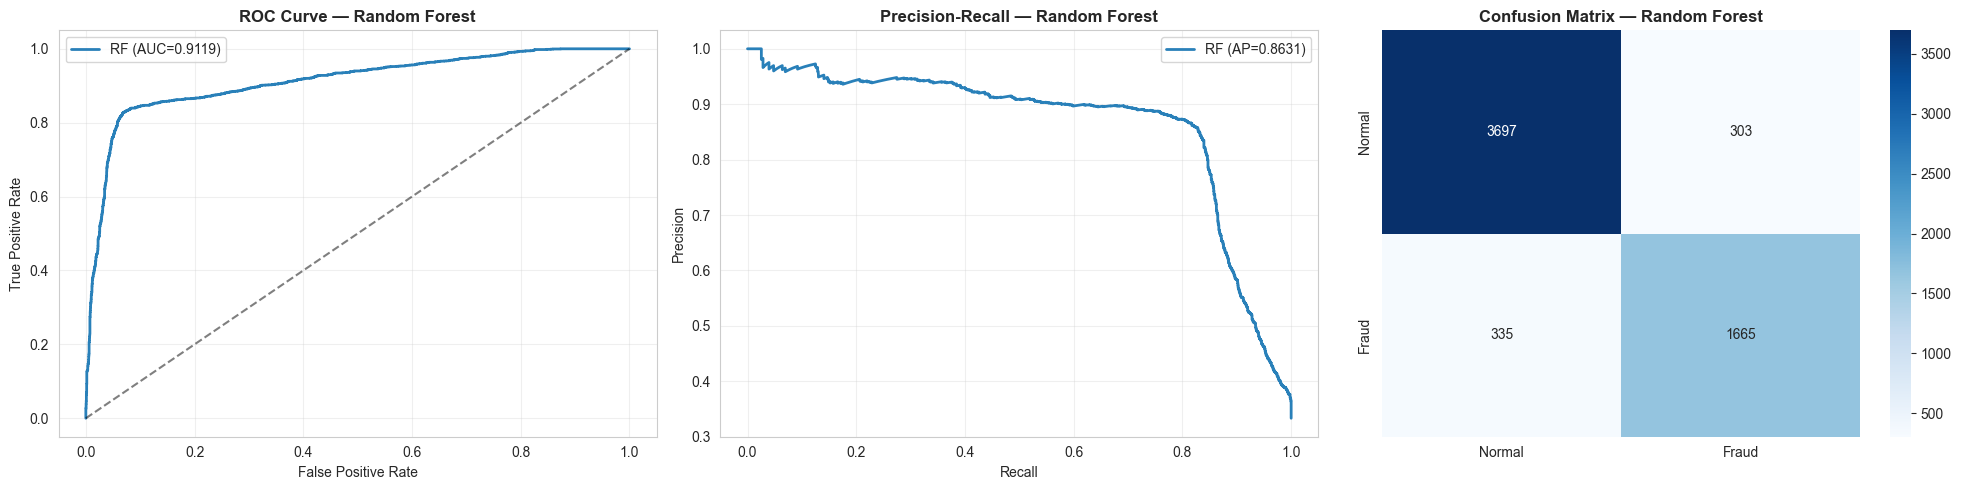

✅ RF evaluation plots saved


In [50]:
# ─── Random Forest — ROC, PR Curve, Confusion Matrix ────────────
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# ROC
fpr, tpr, _ = roc_curve(y_test, rf_proba)
axes[0].plot(fpr, tpr, color="#2980B9", linewidth=2,
             label=f"RF (AUC={roc_auc_score(y_test, rf_proba):.4f})")
axes[0].plot([0,1],[0,1],"k--", alpha=0.5)
axes[0].set_title("ROC Curve — Random Forest", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(); axes[0].grid(alpha=0.3)

# PR
prec, rec, _ = precision_recall_curve(y_test, rf_proba)
ap = average_precision_score(y_test, rf_proba)
axes[1].plot(rec, prec, color="#2980B9", linewidth=2, label=f"RF (AP={ap:.4f})")
axes[1].set_title("Precision-Recall — Random Forest", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend(); axes[1].grid(alpha=0.3)

# Confusion Matrix
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[2],
            xticklabels=["Normal","Fraud"], yticklabels=["Normal","Fraud"])
axes[2].set_title("Confusion Matrix — Random Forest", fontsize=12, fontweight="bold")

plt.tight_layout(); plt.savefig("rf_evaluation.png", dpi=150, bbox_inches="tight")
plt.show(); print("✅ RF evaluation plots saved")

### 🔍 Phase 2 — Overfitting Analysis

**Why overfitting matters in fraud detection:**
A model that overfits memorizes training noise rather than learning true fraud patterns.
In production, it will fail on unseen transactions — the most dangerous failure mode
in AML systems where undetected fraud has direct financial and legal consequences.

**What we measure:**
- **Train AUC** — performance on data the model has seen
- **Test AUC** — performance on held-out data the model has never seen
- **Gap = Train AUC − Test AUC**

**Interpretation:**

| Gap | Classification | Implication |
|-----|---------------|-------------|
| < 5% | No Overfitting | Model generalizes well |
| 5–10% | Moderate Overfitting | Acceptable; consider regularization |
| > 10% | Severe Overfitting | Model memorizing training data |

**Why AUC over Accuracy for this check:**
Accuracy is misleading with imbalanced data. AUC measures ranking ability across all
thresholds — a more honest measure of generalization in fraud detection.

In [51]:
# ─── Random Forest — Overfitting Check ──────────────────────────
overfitting_tt = overfitting_tt if 'overfitting_tt' in dir() else []
result_rf = overfitting_check(
    rf_model, X_train_res, y_train_res,
    X_test_scaled, y_test, rf_pred, rf_proba, "Random Forest"
)
if not any(r["model"] == "Random Forest" for r in overfitting_tt):
    overfitting_tt.append(result_rf)


🔍 Overfitting Check — Random Forest
  Metric               Train       Test        Gap
  ---------------------------------------------
  ROC-AUC             0.9589     0.9119    +0.0470
  F1-Score            0.8874     0.8392    +0.0482

  Verdict: ✅ No Overfitting  (gap < 5%)


### 🔄 Phase 3 — Stratified K-Fold Cross Validation

**Purpose (NOT training):**
K-Fold is an evaluation tool — not a training replacement. It answers:
*"Is this model's performance consistent across different data splits,
or did we get lucky with one particular train/test division?"*

**Why Stratified K-Fold for fraud detection:**
- `StratifiedKFold`: preserves the fraud/normal ratio in every fold — critical because
  the minority class (fraud) must be represented in every validation set
- `n_splits=5`: five non-overlapping validation sets; each transaction is validated exactly once
- `shuffle=True`: randomizes data order before splitting to prevent temporal bias

**Leak-free pipeline inside each fold:**
1. `StandardScaler` is **fit on training fold only** → transform both train and val
2. `SMOTE` is applied on **training fold only** → validation fold sees real class distribution
3. A fresh model clone is trained → no information from previous folds leaks

**What we report:**
- **Mean ROC-AUC** across 5 folds — the reliable performance estimate
- **Standard deviation** — stability indicator; low std = consistent generalization

**Academic justification:**
K-Fold reduces the variance of the performance estimate by a factor of k compared to
a single train/test split (Kohavi, 1995). The final model is then retrained on 100%
of the data using the confirmed hyperparameters.

In [52]:
# ─── Random Forest — K-Fold ─────────────────────────────────────
rf_kf_folds, rf_kf_means, rf_kf_stds = run_kfold(
    rf_base, X_kf, y_kf, "Random Forest"
)


🔄 K-Fold (5 folds) — Random Forest
  Fold        Acc     Prec      Rec       F1      AUC
  ----------------------------------------------
  Fold 1    0.8998   0.8567   0.8400   0.8483   0.9152
  Fold 2    0.9045   0.8594   0.8530   0.8562   0.9258
  Fold 3    0.9030   0.8603   0.8465   0.8533   0.9168
  Fold 4    0.8972   0.8516   0.8375   0.8445   0.9147
  Fold 5    0.8988   0.8566   0.8365   0.8464   0.9118
  ----------------------------------------------
  Mean     0.9007   0.8569   0.8427   0.8497   0.9168
  Std      0.0030   0.0034   0.0070   0.0049   0.0053


### 🔍 Phase 4 — K-Fold Overfitting / Stability Analysis

**What this checks:**
Inside each K-Fold, we evaluate the model on both the **training fold** and the
**validation fold**. The gap between mean training AUC and mean validation AUC
across all 5 folds reveals whether the model consistently overfits — not just once
on a specific split.

**Why this is more reliable than Phase 2:**
The single train/test overfitting check (Phase 2) can be misleading if the split
happened to be particularly easy or hard. K-Fold averages over 5 different splits,
giving a statistically more robust estimate of true overfitting.

**Stability interpretation:**

| AUC Std | Stability | Meaning |
|---------|-----------|---------|
| < 0.02  | Stable    | Consistent across different data subsets |
| 0.02–0.05 | Moderate | Minor sensitivity to data composition |
| > 0.05  | Unstable  | High variance; model is not robust |

A model with low gap AND low std is the ideal choice for production AML deployment.

In [53]:
# ─── Random Forest — K-Fold Overfitting/Stability ───────────────
overfitting_kf = [] if 'overfitting_kf' not in dir() else overfitting_kf
result_rf_kf = kfold_overfitting(rf_kf_folds, "Random Forest")
if not any(r["model"] == "Random Forest" for r in overfitting_kf):
    overfitting_kf.append(result_rf_kf)


🔍 K-Fold Overfitting — Random Forest
  Metric                      Train          Val        Gap
  ------------------------------------------------------
  ROC-AUC                    0.9591       0.9168    +0.0422
  F1-Score                   0.8854       0.8497    +0.0356

  Verdict: ✅ No Overfitting  (gap < 5%)


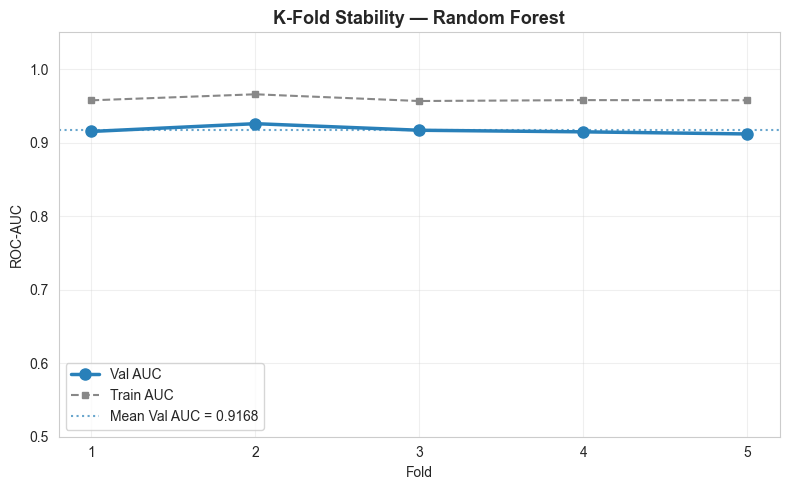

In [54]:
# ─── Random Forest — K-Fold Fold-by-fold Stability ──────────────
fig, ax = plt.subplots(figsize=(8, 5))
folds = rf_kf_folds["fold"].values
ax.plot(folds, rf_kf_folds["roc_auc"],   "o-", color="#2980B9", linewidth=2.5,
        markersize=8, label="Val AUC")
ax.plot(folds, rf_kf_folds["train_auc"], "s--", color="#888", linewidth=1.5,
        markersize=5, label="Train AUC")
ax.axhline(rf_kf_folds["roc_auc"].mean(), color="#2980B9", linestyle=":", alpha=0.7,
           label=f"Mean Val AUC = {rf_kf_folds['roc_auc'].mean():.4f}")
ax.set_title("K-Fold Stability — Random Forest", fontsize=13, fontweight="bold")
ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_xticks(folds); ax.set_ylim(0.5, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("rf_kfold_stability.png", dpi=150, bbox_inches="tight")
plt.show()

---
## ⚡ Model 2 — XGBoost

#### ⚡ XGBoost — Model Explanation

**What it does:**
XGBoost (Extreme Gradient Boosting) builds trees sequentially, where each new tree
corrects the residual errors of the previous ones using gradient descent on a loss function.

**Why it works for fraud detection:**
- Sequential error correction makes it excellent at detecting subtle fraud patterns
  that early trees miss
- `n_estimators=200`: 200 boosting rounds — enough for convergence without overfitting
- `max_depth=8`: shallower than RF by design — boosting corrects errors iteratively,
  so deep individual trees are not needed
- `learning_rate=0.05`: small step size — more conservative updates, better generalization
- `eval_metric='logloss'`: optimizes log-likelihood, well-suited for probability calibration
  in fraud scoring (we need calibrated probabilities for the risk score 0–100)

**Key advantage:** Often outperforms RF on structured tabular data; fast inference.

In [56]:
# ── XGBoost — Train/Test Split ──────────────────────────────────
XGB_PATH = "xgb_aml_model.pkl"

if not os.path.exists(XGB_PATH):
    xgb_model = XGBClassifier(
        n_estimators=200, max_depth=8, learning_rate=0.05,
        eval_metric='logloss', random_state=42, n_jobs=-1
    )
    xgb_model.fit(X_train_res, y_train_res)
    joblib.dump(xgb_model, XGB_PATH)
    print("✅ XGBoost trained and saved")
else:
    xgb_model = joblib.load(XGB_PATH)
    print("⚡ XGBoost loaded from cache")

xgb_pred  = xgb_model.predict(X_test_scaled)
xgb_proba = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("\n" + "="*60)
print("⚡ XGBoost — Test Set Performance")
print("="*60)
print(classification_report(y_test, xgb_pred, target_names=["Normal", "Laundering"]))
print(f"  ROC-AUC : {roc_auc_score(y_test, xgb_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(y_test, xgb_proba):.4f}")
print("="*60)

✅ XGBoost trained and saved

⚡ XGBoost — Test Set Performance
              precision    recall  f1-score   support

      Normal       0.91      0.95      0.93      4000
  Laundering       0.89      0.82      0.85      2000

    accuracy                           0.90      6000
   macro avg       0.90      0.88      0.89      6000
weighted avg       0.90      0.90      0.90      6000

  ROC-AUC : 0.9191
  PR-AUC  : 0.8886


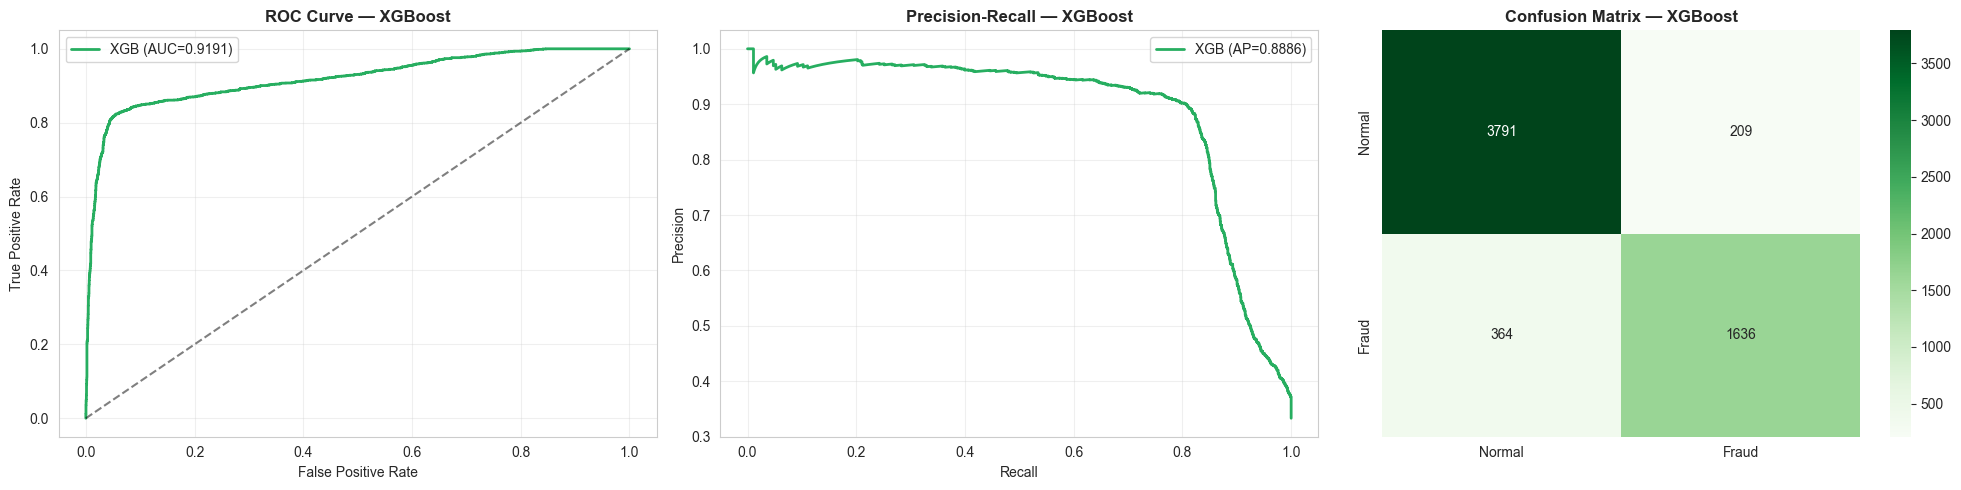

✅ XGB evaluation plots saved


In [58]:
# ─── XGBoost — ROC, PR Curve, Confusion Matrix ──────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

fpr, tpr, _ = roc_curve(y_test, xgb_proba)
axes[0].plot(fpr, tpr, color="#27AE60", linewidth=2,
             label=f"XGB (AUC={roc_auc_score(y_test, xgb_proba):.4f})")
axes[0].plot([0,1],[0,1],"k--", alpha=0.5)
axes[0].set_title("ROC Curve — XGBoost", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].legend(); axes[0].grid(alpha=0.3)

prec, rec, _ = precision_recall_curve(y_test, xgb_proba)
ap = average_precision_score(y_test, xgb_proba)
axes[1].plot(rec, prec, color="#27AE60", linewidth=2, label=f"XGB (AP={ap:.4f})")
axes[1].set_title("Precision-Recall — XGBoost", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend(); axes[1].grid(alpha=0.3)

cm = confusion_matrix(y_test, xgb_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=axes[2],
            xticklabels=["Normal","Fraud"], yticklabels=["Normal","Fraud"])
axes[2].set_title("Confusion Matrix — XGBoost", fontsize=12, fontweight="bold")

plt.tight_layout(); plt.savefig("xgb_evaluation.png", dpi=150, bbox_inches="tight")
plt.show(); print("✅ XGB evaluation plots saved")

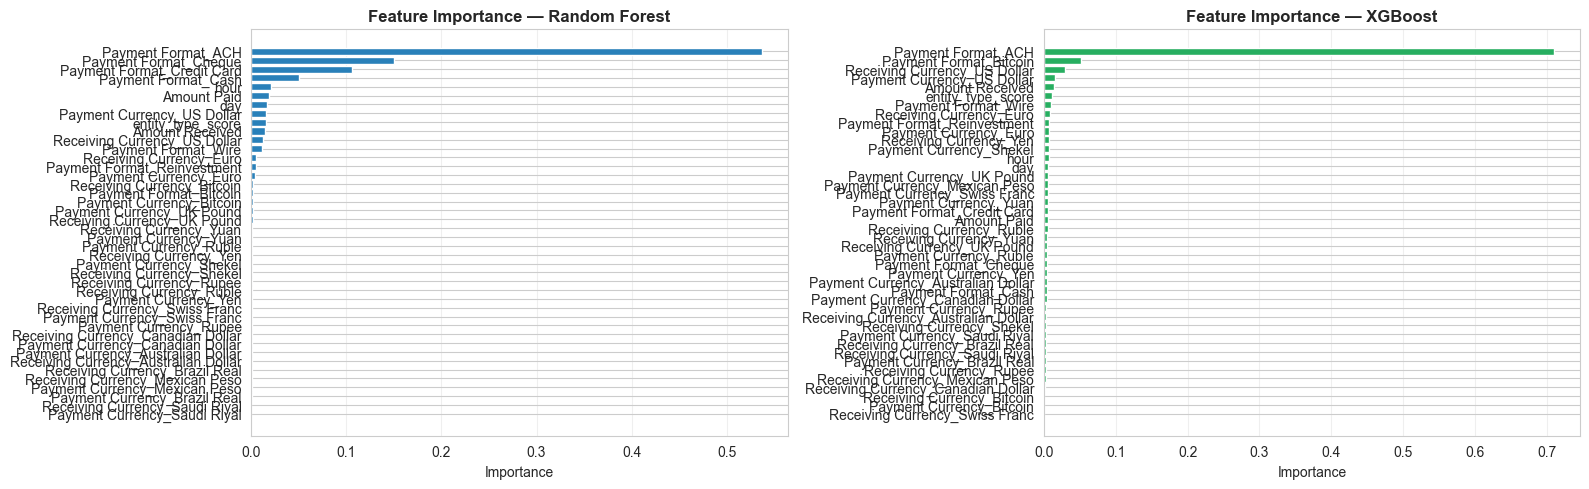

✅ Feature importance saved


In [57]:
# ── Feature Importance — RF & XGBoost ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (model, title, color) in zip(axes, [
    (rf_model,  "Random Forest",  "#2980B9"),
    (xgb_model, "XGBoost",        "#27AE60")
]):
    fi = pd.DataFrame({
        "Feature":    FEATURES,
        "Importance": model.feature_importances_
    }).sort_values("Importance", ascending=True)

    ax.barh(fi["Feature"], fi["Importance"], color=color, edgecolor="white")
    ax.set_title(f"Feature Importance — {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Importance")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Feature importance saved")

### 🔍 Phase 2 — Overfitting Analysis

**Why overfitting matters in fraud detection:**
A model that overfits memorizes training noise rather than learning true fraud patterns.
In production, it will fail on unseen transactions — the most dangerous failure mode
in AML systems where undetected fraud has direct financial and legal consequences.

**What we measure:**
- **Train AUC** — performance on data the model has seen
- **Test AUC** — performance on held-out data the model has never seen
- **Gap = Train AUC − Test AUC**

**Interpretation:**

| Gap | Classification | Implication |
|-----|---------------|-------------|
| < 5% | No Overfitting | Model generalizes well |
| 5–10% | Moderate Overfitting | Acceptable; consider regularization |
| > 10% | Severe Overfitting | Model memorizing training data |

**Why AUC over Accuracy for this check:**
Accuracy is misleading with imbalanced data. AUC measures ranking ability across all
thresholds — a more honest measure of generalization in fraud detection.

In [59]:
# ─── XGBoost — Overfitting Check ───────────────────────────────
result_xgb = overfitting_check(
    xgb_model, X_train_res, y_train_res,
    X_test_scaled, y_test, xgb_pred, xgb_proba, "XGBoost"
)
if not any(r["model"] == "XGBoost" for r in overfitting_tt):
    overfitting_tt.append(result_xgb)


🔍 Overfitting Check — XGBoost
  Metric               Train       Test        Gap
  ---------------------------------------------
  ROC-AUC             0.9756     0.9191    +0.0565
  F1-Score            0.9177     0.8510    +0.0667

  Verdict: 🟡 Moderate Overfitting  (5% ≤ gap < 10%)


### 🔄 Phase 3 — Stratified K-Fold Cross Validation

**Purpose (NOT training):**
K-Fold is an evaluation tool — not a training replacement. It answers:
*"Is this model's performance consistent across different data splits,
or did we get lucky with one particular train/test division?"*

**Why Stratified K-Fold for fraud detection:**
- `StratifiedKFold`: preserves the fraud/normal ratio in every fold — critical because
  the minority class (fraud) must be represented in every validation set
- `n_splits=5`: five non-overlapping validation sets; each transaction is validated exactly once
- `shuffle=True`: randomizes data order before splitting to prevent temporal bias

**Leak-free pipeline inside each fold:**
1. `StandardScaler` is **fit on training fold only** → transform both train and val
2. `SMOTE` is applied on **training fold only** → validation fold sees real class distribution
3. A fresh model clone is trained → no information from previous folds leaks

**What we report:**
- **Mean ROC-AUC** across 5 folds — the reliable performance estimate
- **Standard deviation** — stability indicator; low std = consistent generalization

**Academic justification:**
K-Fold reduces the variance of the performance estimate by a factor of k compared to
a single train/test split (Kohavi, 1995). The final model is then retrained on 100%
of the data using the confirmed hyperparameters.

In [60]:
# ─── XGBoost — K-Fold ───────────────────────────────────────────
xgb_kf_folds, xgb_kf_means, xgb_kf_stds = run_kfold(
    xgb_base, X_kf, y_kf, "XGBoost"
)


🔄 K-Fold (5 folds) — XGBoost
  Fold        Acc     Prec      Rec       F1      AUC
  ----------------------------------------------
  Fold 1    0.9095   0.8949   0.8255   0.8588   0.9248
  Fold 2    0.9170   0.9042   0.8400   0.8709   0.9252
  Fold 3    0.9148   0.9027   0.8345   0.8672   0.9253
  Fold 4    0.9078   0.8938   0.8210   0.8559   0.9226
  Fold 5    0.9077   0.8947   0.8195   0.8554   0.9209
  ----------------------------------------------
  Mean     0.9114   0.8980   0.8281   0.8616   0.9237
  Std      0.0043   0.0050   0.0089   0.0070   0.0020


### 🔍 Phase 4 — K-Fold Overfitting / Stability Analysis

**What this checks:**
Inside each K-Fold, we evaluate the model on both the **training fold** and the
**validation fold**. The gap between mean training AUC and mean validation AUC
across all 5 folds reveals whether the model consistently overfits — not just once
on a specific split.

**Why this is more reliable than Phase 2:**
The single train/test overfitting check (Phase 2) can be misleading if the split
happened to be particularly easy or hard. K-Fold averages over 5 different splits,
giving a statistically more robust estimate of true overfitting.

**Stability interpretation:**

| AUC Std | Stability | Meaning |
|---------|-----------|---------|
| < 0.02  | Stable    | Consistent across different data subsets |
| 0.02–0.05 | Moderate | Minor sensitivity to data composition |
| > 0.05  | Unstable  | High variance; model is not robust |

A model with low gap AND low std is the ideal choice for production AML deployment.

In [61]:
# ─── XGBoost — K-Fold Overfitting/Stability ─────────────────────
result_xgb_kf = kfold_overfitting(xgb_kf_folds, "XGBoost")
if not any(r["model"] == "XGBoost" for r in overfitting_kf):
    overfitting_kf.append(result_xgb_kf)


🔍 K-Fold Overfitting — XGBoost
  Metric                      Train          Val        Gap
  ------------------------------------------------------
  ROC-AUC                    0.9745       0.9237    +0.0507
  F1-Score                   0.9151       0.8616    +0.0534

  Verdict: 🟡 Moderate Overfitting  (5% ≤ gap < 10%)


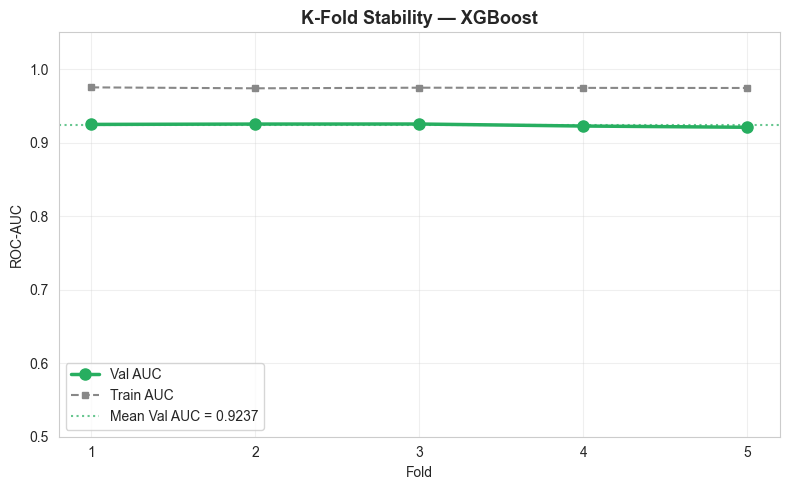

In [62]:
# ─── XGBoost — K-Fold Fold-by-fold Stability ────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
folds = xgb_kf_folds["fold"].values
ax.plot(folds, xgb_kf_folds["roc_auc"],   "o-", color="#27AE60", linewidth=2.5,
        markersize=8, label="Val AUC")
ax.plot(folds, xgb_kf_folds["train_auc"], "s--", color="#888", linewidth=1.5,
        markersize=5, label="Train AUC")
ax.axhline(xgb_kf_folds["roc_auc"].mean(), color="#27AE60", linestyle=":", alpha=0.7,
           label=f"Mean Val AUC = {xgb_kf_folds['roc_auc'].mean():.4f}")
ax.set_title("K-Fold Stability — XGBoost", fontsize=13, fontweight="bold")
ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_xticks(folds); ax.set_ylim(0.5, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("xgb_kfold_stability.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 📈 Model 3 — Logistic Regression

#### 📈 Logistic Regression — Model Explanation

**What it does:**
Logistic Regression models the log-odds of fraud as a linear combination of features,
outputting a probability via the sigmoid function.

**Why it works for fraud detection:**
- Fully interpretable — coefficient signs directly indicate each feature's direction of effect
- `class_weight='none'`: class_weight was set to None to ensure consistency across all models,
  as class imbalance was already handled using SMOTE during the training phase.
  This avoids redundant re-weighting and maintains a uniform experimental setup for fair model comparison.`
- `C=1.0, penalty='l2'`: L2 (Ridge) regularization prevents any single feature from
  dominating the decision boundary — important because Amount Paid spans a wide range
- `solver='lbfgs'`: memory-efficient quasi-Newton solver, appropriate for this dataset size
- Scaling is **essential** for LR: unscaled features cause biased gradients and slow
  convergence (e.g., Amount Paid in millions vs hour in 0–23)

**Key advantage:** Fastest inference; highest interpretability for regulatory reporting.
Coefficients can be directly cited in compliance documentation.

In [63]:
# ── Logistic Regression — Train/Test Split ──────────────────────
LR_PATH = "lr_aml_model.pkl"

if not os.path.exists(LR_PATH):
    lr_model = LogisticRegression(
        max_iter=1000, class_weight=None,
        C=1.0, penalty='l2', solver='lbfgs',
        random_state=42, n_jobs=-1
    )
    lr_model.fit(X_train_res, y_train_res)
    joblib.dump(lr_model, LR_PATH)
    print("✅ Logistic Regression trained and saved")
else:
    lr_model = joblib.load(LR_PATH)
    print("⚡ Logistic Regression loaded from cache")

lr_pred  = lr_model.predict(X_test_scaled)
lr_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

print("\n" + "="*60)
print("📈 Logistic Regression — Test Set Performance")
print("="*60)
print(classification_report(y_test, lr_pred, target_names=["Normal", "Laundering"]))
print(f"  ROC-AUC : {roc_auc_score(y_test, lr_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(y_test, lr_proba):.4f}")
print("="*60)

✅ Logistic Regression trained and saved

📈 Logistic Regression — Test Set Performance
              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92      4000
  Laundering       0.84      0.83      0.84      2000

    accuracy                           0.89      6000
   macro avg       0.88      0.88      0.88      6000
weighted avg       0.89      0.89      0.89      6000

  ROC-AUC : 0.9035
  PR-AUC  : 0.8132


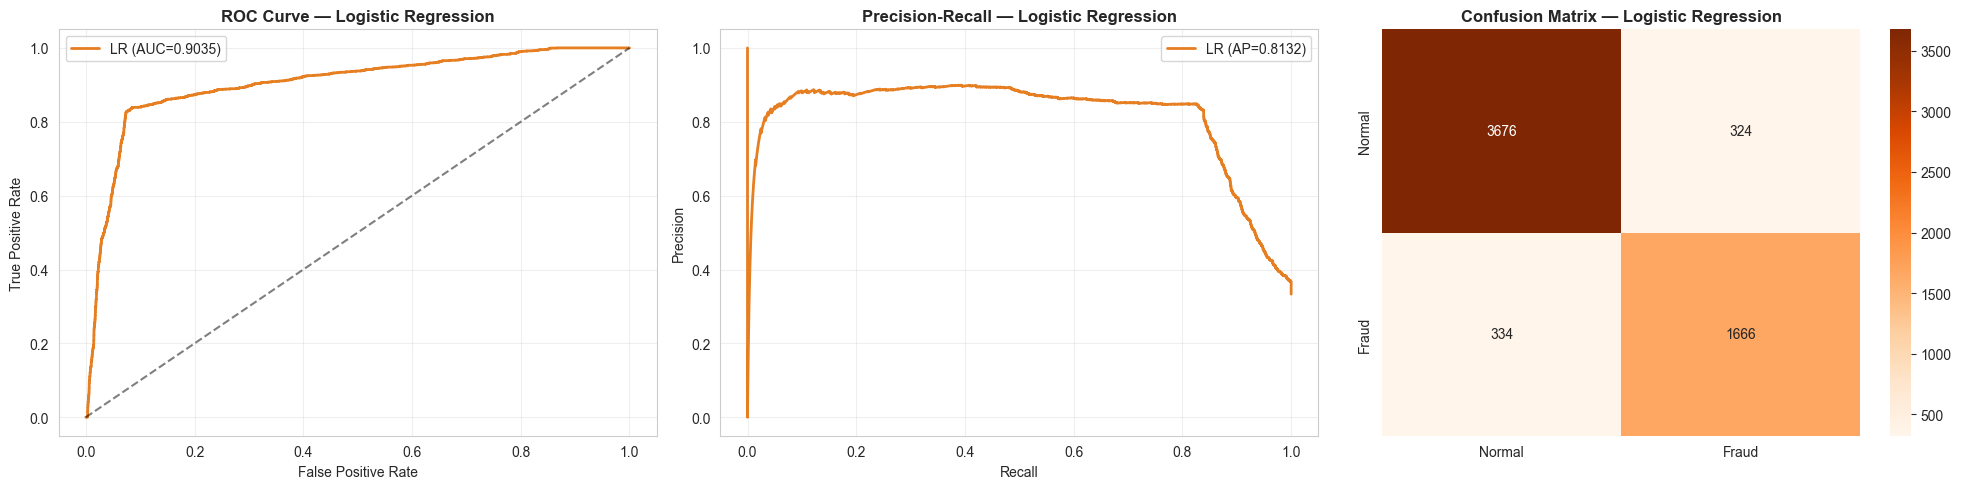

✅ LR evaluation plots saved


In [64]:
# ─── Logistic Regression — ROC, PR Curve, Confusion Matrix ─────
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

fpr, tpr, _ = roc_curve(y_test, lr_proba)
axes[0].plot(fpr, tpr, color="#E67E22", linewidth=2,
             label=f"LR (AUC={roc_auc_score(y_test, lr_proba):.4f})")
axes[0].plot([0,1],[0,1],"k--", alpha=0.5)
axes[0].set_title("ROC Curve — Logistic Regression", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].legend(); axes[0].grid(alpha=0.3)

prec, rec, _ = precision_recall_curve(y_test, lr_proba)
ap = average_precision_score(y_test, lr_proba)
axes[1].plot(rec, prec, color="#E67E22", linewidth=2, label=f"LR (AP={ap:.4f})")
axes[1].set_title("Precision-Recall — Logistic Regression", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend(); axes[1].grid(alpha=0.3)

cm = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", ax=axes[2],
            xticklabels=["Normal","Fraud"], yticklabels=["Normal","Fraud"])
axes[2].set_title("Confusion Matrix — Logistic Regression", fontsize=12, fontweight="bold")

plt.tight_layout(); plt.savefig("lr_evaluation.png", dpi=150, bbox_inches="tight")
plt.show(); print("✅ LR evaluation plots saved")

### 🔍 Phase 2 — Overfitting Analysis

**Why overfitting matters in fraud detection:**
A model that overfits memorizes training noise rather than learning true fraud patterns.
In production, it will fail on unseen transactions — the most dangerous failure mode
in AML systems where undetected fraud has direct financial and legal consequences.

**What we measure:**
- **Train AUC** — performance on data the model has seen
- **Test AUC** — performance on held-out data the model has never seen
- **Gap = Train AUC − Test AUC**

**Interpretation:**

| Gap | Classification | Implication |
|-----|---------------|-------------|
| < 5% | No Overfitting | Model generalizes well |
| 5–10% | Moderate Overfitting | Acceptable; consider regularization |
| > 10% | Severe Overfitting | Model memorizing training data |

**Why AUC over Accuracy for this check:**
Accuracy is misleading with imbalanced data. AUC measures ranking ability across all
thresholds — a more honest measure of generalization in fraud detection.

In [65]:
# ─── Logistic Regression — Overfitting Check ────────────────────
result_lr = overfitting_check(
    lr_model, X_train_res, y_train_res,
    X_test_scaled, y_test, lr_pred, lr_proba, "Logistic Regression"
)
if not any(r["model"] == "Logistic Regression" for r in overfitting_tt):
    overfitting_tt.append(result_lr)


🔍 Overfitting Check — Logistic Regression
  Metric               Train       Test        Gap
  ---------------------------------------------
  ROC-AUC             0.9121     0.9035    +0.0086
  F1-Score            0.8814     0.8351    +0.0463

  Verdict: ✅ No Overfitting  (gap < 5%)


### 🔄 Phase 3 — Stratified K-Fold Cross Validation

**Purpose (NOT training):**
K-Fold is an evaluation tool — not a training replacement. It answers:
*"Is this model's performance consistent across different data splits,
or did we get lucky with one particular train/test division?"*

**Why Stratified K-Fold for fraud detection:**
- `StratifiedKFold`: preserves the fraud/normal ratio in every fold — critical because
  the minority class (fraud) must be represented in every validation set
- `n_splits=5`: five non-overlapping validation sets; each transaction is validated exactly once
- `shuffle=True`: randomizes data order before splitting to prevent temporal bias

**Leak-free pipeline inside each fold:**
1. `StandardScaler` is **fit on training fold only** → transform both train and val
2. `SMOTE` is applied on **training fold only** → validation fold sees real class distribution
3. A fresh model clone is trained → no information from previous folds leaks

**What we report:**
- **Mean ROC-AUC** across 5 folds — the reliable performance estimate
- **Standard deviation** — stability indicator; low std = consistent generalization

**Academic justification:**
K-Fold reduces the variance of the performance estimate by a factor of k compared to
a single train/test split (Kohavi, 1995). The final model is then retrained on 100%
of the data using the confirmed hyperparameters.

In [66]:
# ─── Logistic Regression — K-Fold ───────────────────────────────
lr_kf_folds, lr_kf_means, lr_kf_stds = run_kfold(
    lr_base, X_kf, y_kf, "Logistic Regression"
)


🔄 K-Fold (5 folds) — Logistic Regression
  Fold        Acc     Prec      Rec       F1      AUC
  ----------------------------------------------
  Fold 1    0.8972   0.8480   0.8425   0.8452   0.9094
  Fold 2    0.9012   0.8502   0.8540   0.8521   0.9119
  Fold 3    0.8992   0.8532   0.8425   0.8478   0.9104
  Fold 4    0.8947   0.8410   0.8435   0.8422   0.9086
  Fold 5    0.8932   0.8430   0.8350   0.8390   0.9053
  ----------------------------------------------
  Mean     0.8971   0.8471   0.8435   0.8453   0.9091
  Std      0.0032   0.0050   0.0068   0.0050   0.0025


### 🔍 Phase 4 — K-Fold Overfitting / Stability Analysis

**What this checks:**
Inside each K-Fold, we evaluate the model on both the **training fold** and the
**validation fold**. The gap between mean training AUC and mean validation AUC
across all 5 folds reveals whether the model consistently overfits — not just once
on a specific split.

**Why this is more reliable than Phase 2:**
The single train/test overfitting check (Phase 2) can be misleading if the split
happened to be particularly easy or hard. K-Fold averages over 5 different splits,
giving a statistically more robust estimate of true overfitting.

**Stability interpretation:**

| AUC Std | Stability | Meaning |
|---------|-----------|---------|
| < 0.02  | Stable    | Consistent across different data subsets |
| 0.02–0.05 | Moderate | Minor sensitivity to data composition |
| > 0.05  | Unstable  | High variance; model is not robust |

A model with low gap AND low std is the ideal choice for production AML deployment.

In [67]:
# ─── Logistic Regression — K-Fold Overfitting/Stability ─────────
result_lr_kf = kfold_overfitting(lr_kf_folds, "Logistic Regression")
if not any(r["model"] == "Logistic Regression" for r in overfitting_kf):
    overfitting_kf.append(result_lr_kf)


🔍 K-Fold Overfitting — Logistic Regression
  Metric                      Train          Val        Gap
  ------------------------------------------------------
  ROC-AUC                    0.9098       0.9091    +0.0007
  F1-Score                   0.8784       0.8453    +0.0331

  Verdict: ✅ No Overfitting  (gap < 5%)


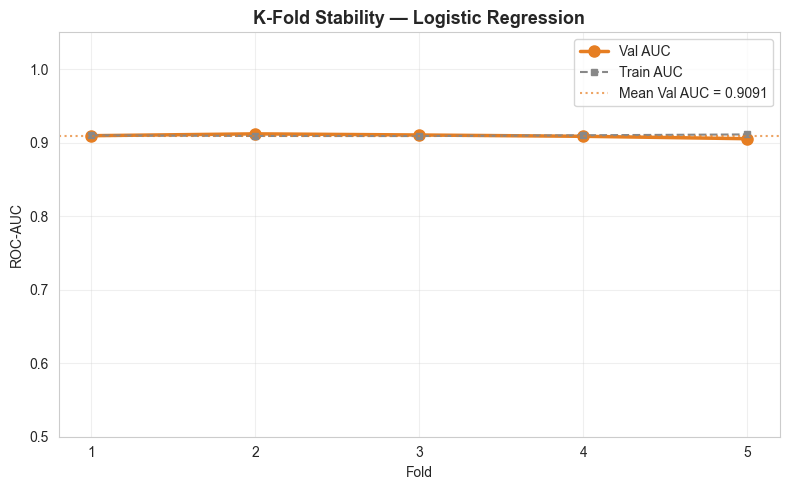

In [68]:
# ─── Logistic Regression — K-Fold Fold-by-fold Stability ────────
fig, ax = plt.subplots(figsize=(8, 5))
folds = lr_kf_folds["fold"].values
ax.plot(folds, lr_kf_folds["roc_auc"],   "o-", color="#E67E22", linewidth=2.5,
        markersize=8, label="Val AUC")
ax.plot(folds, lr_kf_folds["train_auc"], "s--", color="#888", linewidth=1.5,
        markersize=5, label="Train AUC")
ax.axhline(lr_kf_folds["roc_auc"].mean(), color="#E67E22", linestyle=":", alpha=0.7,
           label=f"Mean Val AUC = {lr_kf_folds['roc_auc'].mean():.4f}")
ax.set_title("K-Fold Stability — Logistic Regression", fontsize=13, fontweight="bold")
ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_xticks(folds); ax.set_ylim(0.5, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("lr_kfold_stability.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 🏆 Final Comparison — All Models

In [69]:
# ═══════════════════════════════════════════════════════════════
# PHASE 5: Final Comparison — Train/Test Split vs K-Fold
# ═══════════════════════════════════════════════════════════════

def make_comparison():
    rows = []
    models_tt = [
        ("Random Forest",       rf_pred,  rf_proba),
        ("XGBoost",             xgb_pred, xgb_proba),
        ("Logistic Regression", lr_pred,  lr_proba),
    ]
    kf_means_map = {
        "Random Forest":       rf_kf_means,
        "XGBoost":             xgb_kf_means,
        "Logistic Regression": lr_kf_means,
    }
    tt_gap_map = {r["model"]: r["auc_gap"] for r in overfitting_tt}
    kf_gap_map = {r["model"]: r["auc_gap"] for r in overfitting_kf}

    for name, pred, proba in models_tt:
        km = kf_means_map[name]
        rows.append({
            "Model":              name,
            # Train/Test
            "TT Accuracy":        round(accuracy_score(y_test, pred), 4),
            "TT Precision":       round(precision_score(y_test, pred, zero_division=0), 4),
            "TT Recall":          round(recall_score(y_test, pred), 4),
            "TT F1":              round(f1_score(y_test, pred), 4),
            "TT ROC-AUC":         round(roc_auc_score(y_test, proba), 4),
            "TT PR-AUC":          round(average_precision_score(y_test, proba), 4),
            "TT Gap":             round(tt_gap_map[name], 4),
            # K-Fold
            "KF Accuracy":        round(km["accuracy"], 4),
            "KF Precision":       round(km["precision"], 4),
            "KF Recall":          round(km["recall"], 4),
            "KF F1":              round(km["f1"], 4),
            "KF ROC-AUC":         round(km["roc_auc"], 4),
            "KF Gap":             round(kf_gap_map[name], 4),
        })
    return pd.DataFrame(rows)

comparison = make_comparison()

print("\n" + "="*110)
print("🏆 FINAL MODEL COMPARISON — Train/Test Split vs Stratified K-Fold (k=5)")
print("="*110)
cols_display = ["Model",
                "TT ROC-AUC", "TT F1", "TT Precision", "TT Recall", "TT PR-AUC", "TT Gap",
                "KF ROC-AUC", "KF F1", "KF Precision", "KF Recall", "KF Gap"]
print(comparison[cols_display].to_string(index=False))
print("="*110)


🏆 FINAL MODEL COMPARISON — Train/Test Split vs Stratified K-Fold (k=5)
              Model  TT ROC-AUC  TT F1  TT Precision  TT Recall  TT PR-AUC  TT Gap  KF ROC-AUC  KF F1  KF Precision  KF Recall  KF Gap
      Random Forest      0.9119 0.8392        0.8460     0.8325     0.8631  0.0470      0.9168 0.8497        0.8569     0.8427  0.0422
            XGBoost      0.9191 0.8510        0.8867     0.8180     0.8886  0.0565      0.9237 0.8616        0.8980     0.8281  0.0507
Logistic Regression      0.9035 0.8351        0.8372     0.8330     0.8132  0.0086      0.9091 0.8453        0.8471     0.8435  0.0007


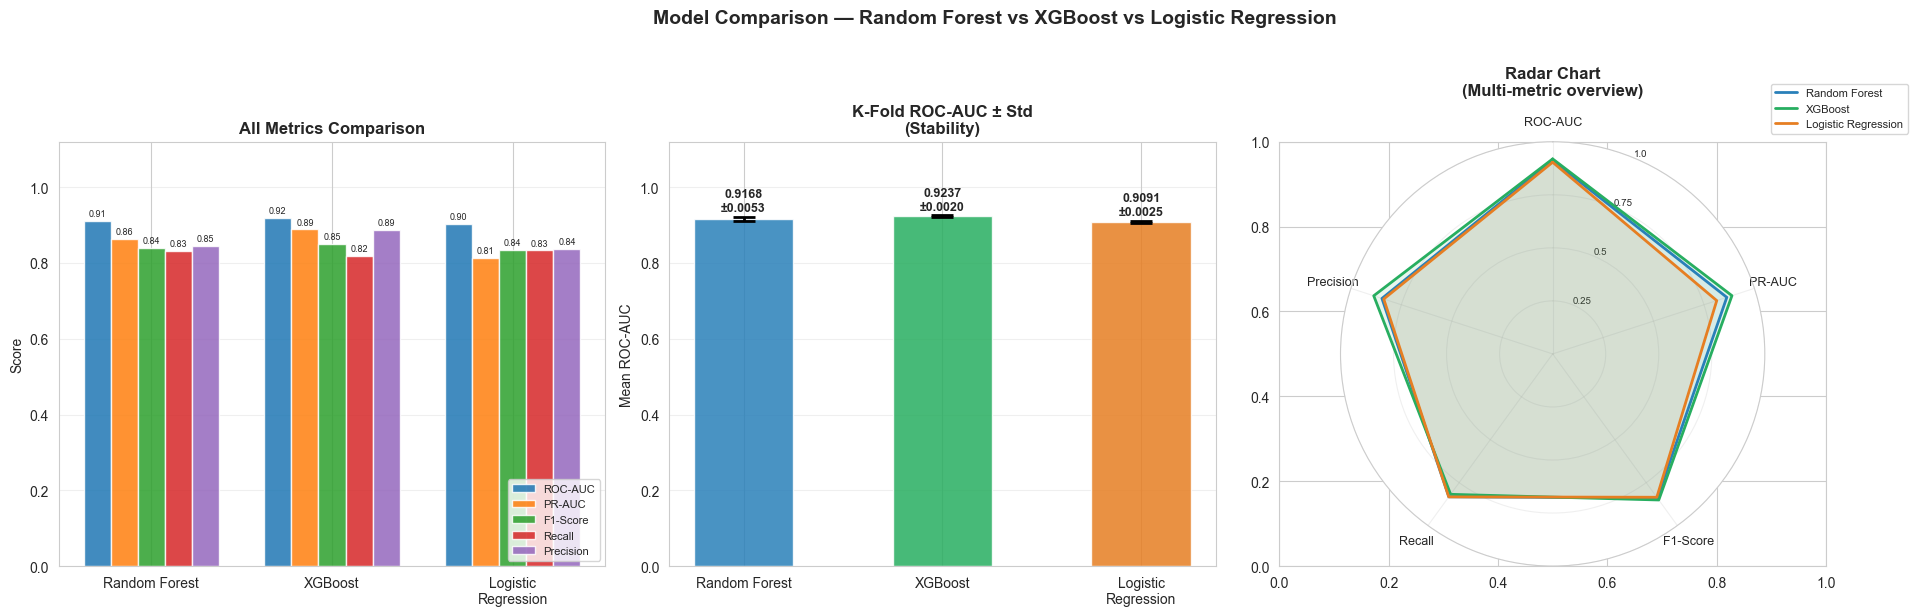

✅ Saved: model_comparison.png


In [70]:
import matplotlib.pyplot as plt
import numpy as np

# ── Data ──────────────────────────────────────────────────────────
models  = ['Random Forest', 'XGBoost', 'Logistic\nRegression']
metrics = {
    'ROC-AUC':   [roc_auc_score(y_test, rf_proba),
                  roc_auc_score(y_test, xgb_proba),
                  roc_auc_score(y_test, lr_proba)],
    'PR-AUC':    [average_precision_score(y_test, rf_proba),
                  average_precision_score(y_test, xgb_proba),
                  average_precision_score(y_test, lr_proba)],
    'F1-Score':  [f1_score(y_test, rf_pred),
                  f1_score(y_test, xgb_pred),
                  f1_score(y_test, lr_pred)],
    'Recall':    [recall_score(y_test, rf_pred),
                  recall_score(y_test, xgb_pred),
                  recall_score(y_test, lr_pred)],
    'Precision': [precision_score(y_test, rf_pred, zero_division=0),
                  precision_score(y_test, xgb_pred, zero_division=0),
                  precision_score(y_test, lr_pred, zero_division=0)],
}
kf_auc = [rf_kf_means['roc_auc'],
           xgb_kf_means['roc_auc'],
           lr_kf_means['roc_auc']]
kf_std = [rf_kf_stds['roc_auc'],
           xgb_kf_stds['roc_auc'],
           lr_kf_stds['roc_auc']]

colors = ['#2980B9', '#27AE60', '#E67E22']
x = np.arange(len(models))
w = 0.15

# ── Figure ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Model Comparison — Random Forest vs XGBoost vs Logistic Regression',
             fontsize=14, fontweight='bold', y=1.02)

# ── Plot 1: All metrics grouped bar ──────────────────────────────
ax = axes[0]
offsets = np.linspace(-(len(metrics)-1)*w/2, (len(metrics)-1)*w/2, len(metrics))
for i, (metric, vals) in enumerate(metrics.items()):
    ax.bar(x + offsets[i], vals, width=w, label=metric, alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(models, fontsize=10)
ax.set_ylabel('Score'); ax.set_ylim(0, 1.12)
ax.set_title('All Metrics Comparison', fontweight='bold')
ax.legend(fontsize=8, loc='lower right')
ax.grid(axis='y', alpha=0.3)
for bar_group in ax.containers:
    ax.bar_label(bar_group, fmt='%.2f', fontsize=6.5, padding=2)

# ── Plot 2: K-Fold AUC with error bars ───────────────────────────
ax = axes[1]
ax.bar(x, kf_auc, color=colors, alpha=0.85, width=0.5,
       yerr=kf_std, capsize=8, error_kw=dict(lw=2, capthick=2))
ax.set_xticks(x); ax.set_xticklabels(models, fontsize=10)
ax.set_ylabel('Mean ROC-AUC'); ax.set_ylim(0, 1.12)
ax.set_title('K-Fold ROC-AUC ± Std\n(Stability)', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
for i, (v, s) in enumerate(zip(kf_auc, kf_std)):
    ax.text(i, v + s + 0.015, f'{v:.4f}\n±{s:.4f}',
            ha='center', fontsize=9, fontweight='bold')

# ── Plot 3: Radar chart ───────────────────────────────────────────
ax = axes[2]
radar_metrics = ['ROC-AUC', 'PR-AUC', 'F1-Score', 'Recall', 'Precision']
N = len(radar_metrics)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]   # close the polygon

ax = plt.subplot(1, 3, 3, polar=True)
ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), radar_metrics, fontsize=9)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['0.25', '0.5', '0.75', '1.0'], fontsize=7)
ax.grid(alpha=0.3)

for model_name, color, vals_dict in zip(
    ['Random Forest', 'XGBoost', 'Logistic Regression'],
    colors,
    [{'ROC-AUC': metrics['ROC-AUC'][0], 'PR-AUC': metrics['PR-AUC'][0],
      'F1-Score': metrics['F1-Score'][0], 'Recall': metrics['Recall'][0],
      'Precision': metrics['Precision'][0]},
     {'ROC-AUC': metrics['ROC-AUC'][1], 'PR-AUC': metrics['PR-AUC'][1],
      'F1-Score': metrics['F1-Score'][1], 'Recall': metrics['Recall'][1],
      'Precision': metrics['Precision'][1]},
     {'ROC-AUC': metrics['ROC-AUC'][2], 'PR-AUC': metrics['PR-AUC'][2],
      'F1-Score': metrics['F1-Score'][2], 'Recall': metrics['Recall'][2],
      'Precision': metrics['Precision'][2]}]
):
    vals = [vals_dict[m] for m in radar_metrics] + [vals_dict[radar_metrics[0]]]
    ax.plot(angles, vals, color=color, linewidth=2, label=model_name)
    ax.fill(angles, vals, color=color, alpha=0.1)

ax.set_title('Radar Chart\n(Multi-metric overview)', fontweight='bold', pad=15)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=8)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: model_comparison.png")

In [71]:
# ── Academic Conclusion ─────────────────────────────────────────
print("\n" + "="*80)
print("📋 ACADEMIC CONCLUSION")
print("="*80)

# Best by K-Fold AUC (more reliable)
best_kf = comparison.loc[comparison["KF ROC-AUC"].idxmax()]
best_tt = comparison.loc[comparison["TT ROC-AUC"].idxmax()]
least_overfit = comparison.loc[comparison["KF Gap"].idxmin()]

print(f"""
1. BEST GENERALIZATION (K-Fold ROC-AUC):
   {best_kf["Model"]} — KF AUC = {best_kf["KF ROC-AUC"]:.4f}

2. BEST TRAIN/TEST PERFORMANCE:
   {best_tt["Model"]} — TT AUC = {best_tt["TT ROC-AUC"]:.4f}

3. LEAST OVERFITTING (K-Fold):
   {least_overfit["Model"]} — KF Gap = {least_overfit["KF Gap"]:.4f}

4. VALIDATION STRATEGY:
   Stratified K-Fold cross-validation provides a more robust and reliable
   evaluation compared to a single train/test split, as it reduces variance
   caused by a single random partition and provides performance stability
   across multiple folds.

5. DATA BALANCING APPROACH:
   Class imbalance was addressed using SMOTE applied strictly within the
   training partitions to prevent data leakage and ensure realistic evaluation
   of model generalization on unseen data.

6. FEATURE SCALING:
   StandardScaler was applied within the training data only to ensure that
   test folds remain completely unseen during preprocessing, which is
   particularly important for linear models such as Logistic Regression.
""")
print("="*80)


📋 ACADEMIC CONCLUSION

1. BEST GENERALIZATION (K-Fold ROC-AUC):
   XGBoost — KF AUC = 0.9237

2. BEST TRAIN/TEST PERFORMANCE:
   XGBoost — TT AUC = 0.9191

3. LEAST OVERFITTING (K-Fold):
   Logistic Regression — KF Gap = 0.0007

4. VALIDATION STRATEGY:
   Stratified K-Fold cross-validation provides a more robust and reliable
   evaluation compared to a single train/test split, as it reduces variance
   caused by a single random partition and provides performance stability
   across multiple folds.

5. DATA BALANCING APPROACH:
   Class imbalance was addressed using SMOTE applied strictly within the
   training partitions to prevent data leakage and ensure realistic evaluation
   of model generalization on unseen data.

6. FEATURE SCALING:
   StandardScaler was applied within the training data only to ensure that
   test folds remain completely unseen during preprocessing, which is
   particularly important for linear models such as Logistic Regression.



---
### 🏁 Final Training — Retrain on 100% of Data

After K-Fold confirmed stability, retrain each model on the full dataset.

> **Note on the deployed models.** The cell below retrains the three models on 100% of the sample, but the *Save Models & Scaler* cell after it saves `rf_model`, `xgb_model`, `lr_model` and `scaler` again, overwriting those files. The models used by the application (`app/models/`) are therefore the **train/test-split models** (trained on the 80% partition), whose held-out test metrics are reported in the comparison table above.
>
> Also note that in the K-Fold base models Logistic Regression uses `class_weight='balanced'`, while the train/test Logistic Regression uses `class_weight=None`.


In [72]:
# Remove old Train/Test models before saving final ones
import os
for f in ["rf_aml_model.pkl", "xgb_aml_model.pkl",
          "lr_aml_model.pkl", "scaler_aml.pkl"]:
    if os.path.exists(f):
        os.remove(f)
        print(f"Deleted old model: {f}")

# ═══════════════════════════════════════════════════════════════
# FINAL TRAINING — Retrain on 100% of data after K-Fold validation
# K-Fold is used only for evaluation and stability checking.
# Final model is retrained on full dataset for deployment.
# This is the model saved for the application
# ═══════════════════════════════════════════════════════════════
from sklearn.base import clone

print("="*60)
print("FINAL TRAINING — 100% of data")
print("="*60)
print(f"Full dataset: {X_kf.shape}")

# Step 1: Scale full data
final_scaler = StandardScaler()
X_full_scaled = final_scaler.fit_transform(X_kf)

# Step 2: SMOTE on full data
X_full_res, y_full_res = SMOTE(random_state=42).fit_resample(
    X_full_scaled, y_kf
)
print(f"After SMOTE : {X_full_res.shape}")

# Step 3: Train on full data using same hyperparameters
final_rf  = clone(rf_base)
final_xgb = clone(xgb_base)
final_lr  = clone(lr_base)

final_rf.fit( X_full_res, y_full_res)
final_xgb.fit(X_full_res, y_full_res)
final_lr.fit( X_full_res, y_full_res)

print("\n✅ Final models trained on 100% of data")

# Step 4: Save — these replace the Train/Test models
joblib.dump(final_rf,     "rf_aml_model.pkl")
joblib.dump(final_xgb,    "xgb_aml_model.pkl")
joblib.dump(final_lr,     "lr_aml_model.pkl")
joblib.dump(final_scaler, "scaler_aml.pkl")

print("\n✅ Saved (K-Fold validated + full-data trained):")
print("   rf_aml_model.pkl")
print("   xgb_aml_model.pkl")
print("   lr_aml_model.pkl")
print("   scaler_aml.pkl")

Deleted old model: rf_aml_model.pkl
Deleted old model: xgb_aml_model.pkl
Deleted old model: lr_aml_model.pkl
FINAL TRAINING — 100% of data
Full dataset: (30000, 42)
After SMOTE : (40000, 42)

✅ Final models trained on 100% of data

✅ Saved (K-Fold validated + full-data trained):
   rf_aml_model.pkl
   xgb_aml_model.pkl
   lr_aml_model.pkl
   scaler_aml.pkl


### 💾 Save Models & Scaler

In [73]:
# ── Save all models, scaler, features ────────────────────────────
import json

joblib.dump(rf_model,  "rf_aml_model.pkl")
joblib.dump(xgb_model, "xgb_aml_model.pkl")
joblib.dump(lr_model,  "lr_aml_model.pkl")
joblib.dump(scaler,    "scaler_aml.pkl")

with open("aml_features.json", "w") as f:
    json.dump(FEATURES, f, indent=2)

comparison.to_csv("model_comparison.csv", index=False)

print("✅ Saved:")
print("   rf_aml_model.pkl")
print("   xgb_aml_model.pkl")
print("   lr_aml_model.pkl")
print("   scaler_aml.pkl")
print("   aml_features.json")
print("   model_comparison.csv")

✅ Saved:
   rf_aml_model.pkl
   xgb_aml_model.pkl
   lr_aml_model.pkl
   scaler_aml.pkl
   aml_features.json
   model_comparison.csv
